## Cell 0: setup 

In [57]:
# 10_protocol_ladder - Cell 0: setup (read-only access to the frozen strict-protocol results)
from pathlib import Path
import sys, yaml, json, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, confusion_matrix

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from circmtl.graph import GraphData
with open(PROJECT_ROOT / "configs" / "paths.yaml", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)
D = PROJECT_ROOT / cfg["outputs"]["processed_dir"] / "dataset_v1"
OLD = D / "train_results"                         # frozen strict-protocol results: READ ONLY
OUT = D / "train_results_ladder"; OUT.mkdir(exist_ok=True)
assert OLD.exists() and OLD != OUT
LAD = yaml.safe_load(open(PROJECT_ROOT / "configs" / "protocol_ladder.yaml", encoding="utf-8"))   # fails if the yaml is missing or invalid
gd = GraphData(D, D / "graph")
print("ladder yaml loaded; runs:", list(LAD["runs"]), "| metrics:", LAD["metrics"])
print("frozen results:", len(list(OLD.glob("pred_*.csv"))), "prediction files")

ladder yaml loaded; runs: ['S0', 'B', 'A', 'C', 'C2', 'X'] | metrics: ['AUROC', 'AUPR', 'accuracy', 'precision', 'recall', 'specificity', 'F1', 'MCC', 'confusion matrix', 'ROC curve']
frozen results: 165 prediction files


## Cell 1:  metric report

S0 predictions: 257584 rows | ['M1', 'M2', 'M3'] | seeds [np.int64(0), np.int64(1), np.int64(2)]
[S0] disease task | degree_matched negatives | threshold = 0.0 (model logit) | mean over seeds (range)
                              AUROC                 AUPR             Accuracy            Precision               Recall          Specificity                   F1                  MCC
M1              0.521 (0.515-0.525)  0.514 (0.508-0.521)  0.514 (0.509-0.521)  0.522 (0.513-0.531)  0.340 (0.324-0.357)  0.689 (0.679-0.701)  0.411 (0.399-0.427)  0.030 (0.019-0.045)
M2              0.520 (0.500-0.535)  0.511 (0.495-0.520)  0.514 (0.504-0.519)  0.520 (0.506-0.528)  0.352 (0.334-0.371)  0.676 (0.666-0.686)  0.420 (0.402-0.435)  0.029 (0.008-0.039)
M3              0.530 (0.516-0.543)  0.523 (0.515-0.530)  0.520 (0.508-0.532)  0.528 (0.510-0.544)  0.382 (0.343-0.404)  0.658 (0.612-0.695)  0.442 (0.417-0.460)  0.042 (0.016-0.067)
disease_degree  0.510 (0.508-0.513)  0.512 (0.511-0.513)            

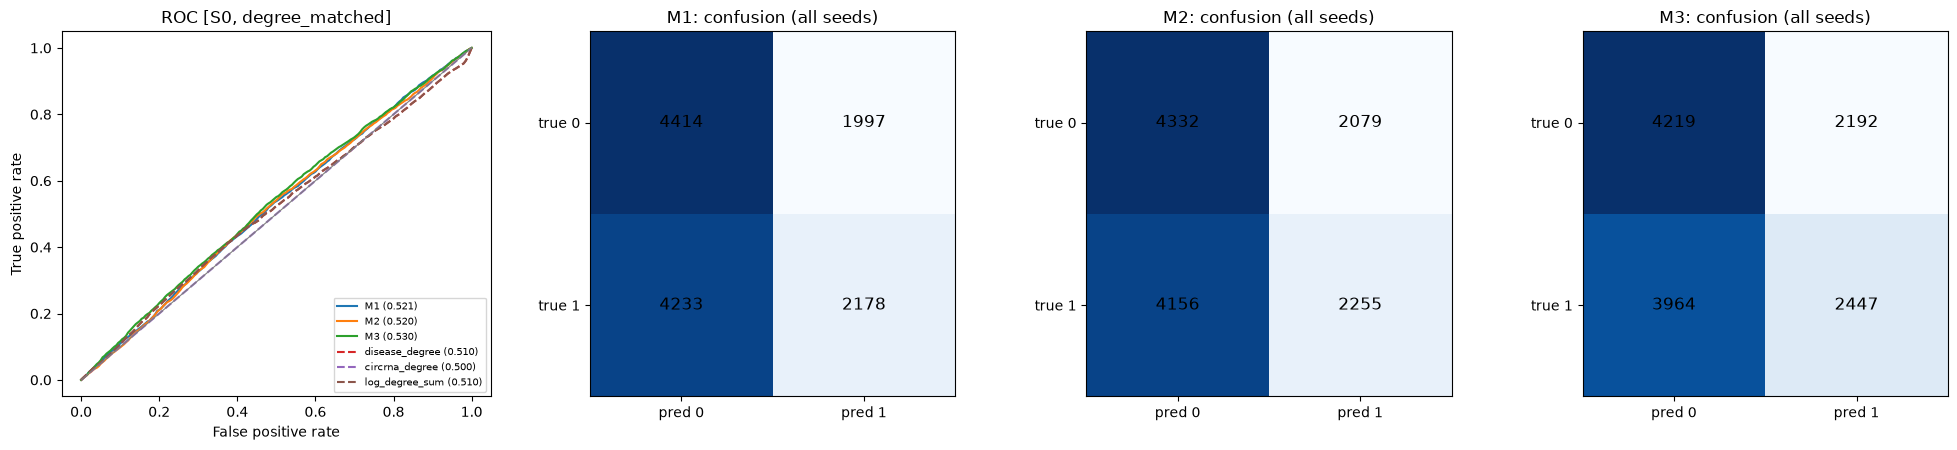

[S0] disease task | random negatives | threshold = 0.0 (model logit) | mean over seeds (range)
                              AUROC                 AUPR             Accuracy            Precision               Recall          Specificity                   F1                     MCC
M1              0.513 (0.500-0.524)  0.487 (0.474-0.497)  0.480 (0.476-0.483)  0.473 (0.469-0.475)  0.340 (0.324-0.357)  0.621 (0.595-0.642)  0.395 (0.385-0.405)  -0.041 (-0.049--0.036)
M2              0.502 (0.480-0.518)  0.476 (0.458-0.490)  0.474 (0.456-0.489)  0.465 (0.442-0.485)  0.352 (0.334-0.371)  0.595 (0.578-0.606)  0.400 (0.380-0.421)  -0.055 (-0.091--0.023)
M3              0.551 (0.542-0.557)  0.511 (0.507-0.520)  0.508 (0.499-0.517)  0.511 (0.498-0.522)  0.382 (0.343-0.404)  0.635 (0.615-0.654)  0.437 (0.407-0.452)    0.017 (-0.003-0.035)
disease_degree  0.820 (0.816-0.822)  0.823 (0.814-0.832)                  n/a                  n/a                  n/a                  n/a                  n/a

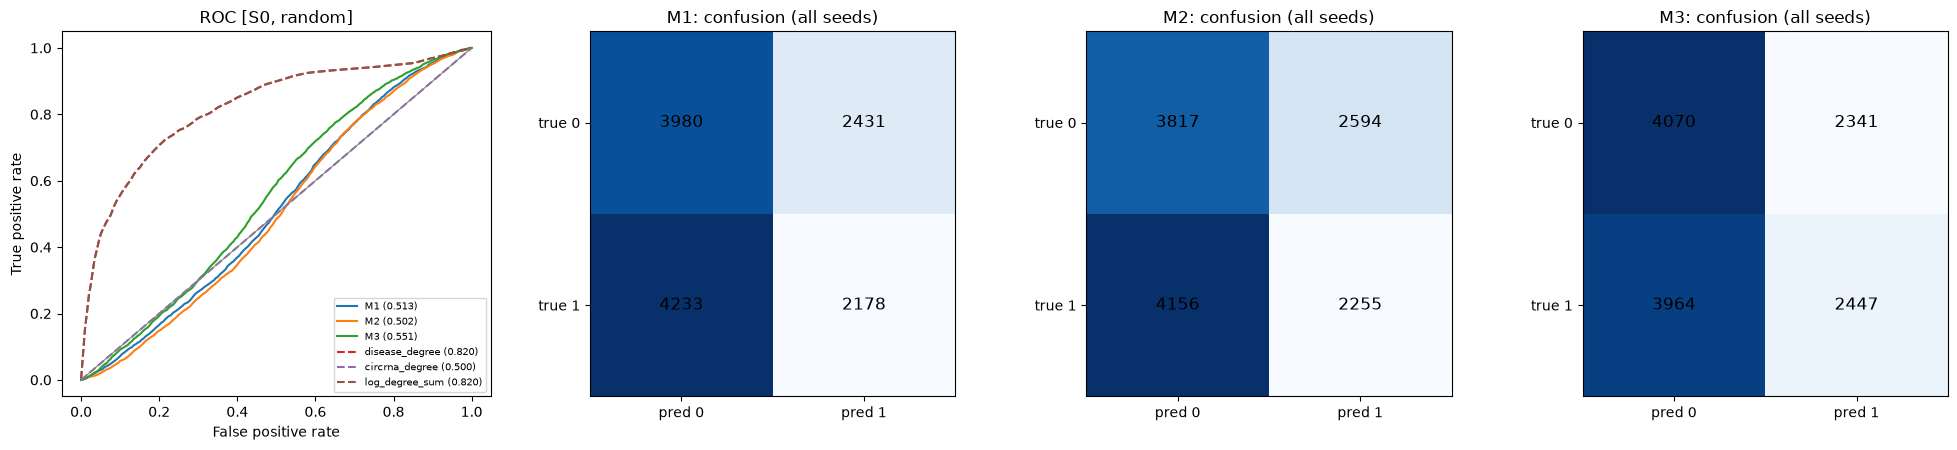

In [8]:
# 10_protocol_ladder - Cell 1: metric report (reusable for every run) and the S0 reference row
def mcc_from(tp, tn, fp, fn):
    den = np.sqrt(float(tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    return float((tp * tn - fp * fn) / den) if den > 0 else 0.0

def baseline_scores(d, kind):
    """popularity baselines from the fold's TRAINING pairs only; d has columns seed, fold, c, t and a RangeIndex"""
    out = np.zeros(len(d))
    for (s, k), ix in d.groupby(["seed", "fold"]).indices.items():
        tr = gd.load_fold(s, k)["disease_train"]
        dd = np.bincount(tr[:, 1], minlength=gd.N["disease"]); cd = np.bincount(tr[:, 0], minlength=gd.N["circRNA"])
        c, t = d["c"].to_numpy()[ix], d["t"].to_numpy()[ix]
        out[ix] = {"disease_degree": dd[t], "circrna_degree": cd[c], "log_degree_sum": np.log1p(dd[t]) + np.log1p(cd[c])}[kind]
    return out

def report(P, models, tag, scheme="degree_matched", task="disease", threshold=0.0,
           baselines=("disease_degree", "circrna_degree", "log_degree_sum")):
    d = P[(P["task"] == task) & (P["scheme"] == scheme) & P["model"].isin(models)].reset_index(drop=True)
    assert set(models) <= set(d["model"]), f"missing predictions for {set(models) - set(d['model'])}"
    base = d[d["model"] == models[0]][["seed", "fold", "c", "t", "y"]].reset_index(drop=True)
    keep = ["model", "seed", "fold", "c", "t", "y", "score", "score_rank"] + (["threshold"] if "threshold" in d else [])
    parts = [d[keep]]
    for b in baselines:
        x = base.copy(); x["score"] = baseline_scores(x, b); x["model"] = b
        x["score_rank"] = x.groupby(["seed", "fold"])["score"].rank(pct=True)
        parts.append(x)
    A = pd.concat(parts, ignore_index=True)
    rows = []
    for (m, s), g in A.groupby(["model", "seed"], sort=False):
        r = {"model": m, "seed": s, "AUROC": roc_auc_score(g["y"], g["score_rank"]), "AUPR": average_precision_score(g["y"], g["score_rank"])}
        if m in models:                                              # threshold metrics only for the models
            thr = g["threshold"].to_numpy() if "threshold" in g else threshold      # per-fold validation-chosen threshold if present
            yhat = (g["score"].to_numpy() > thr).astype(int)
            tn, fp, fn, tp = confusion_matrix(g["y"], yhat, labels=[0, 1]).ravel()
            r.update(TP=tp, FP=fp, TN=tn, FN=fn, Accuracy=(tp + tn) / len(g),
                     Precision=tp / (tp + fp) if tp + fp else np.nan, Recall=tp / (tp + fn) if tp + fn else np.nan,
                     Specificity=tn / (tn + fp) if tn + fp else np.nan, F1=2 * tp / (2 * tp + fp + fn) if tp else 0.0,
                     MCC=mcc_from(tp, tn, fp, fn))
        rows.append(r)
    per_seed = pd.DataFrame(rows)
    cols = [c for c in ["AUROC", "AUPR", "Accuracy", "Precision", "Recall", "Specificity", "F1", "MCC"] if c in per_seed]
    order = list(models) + list(baselines)
    tab = {}
    for c in cols:
        agg = per_seed.groupby("model")[c].agg(["mean", "min", "max"])
        tab[c] = [f"{agg.loc[m, 'mean']:.3f} ({agg.loc[m, 'min']:.3f}-{agg.loc[m, 'max']:.3f})" if m in agg.index and pd.notna(agg.loc[m, 'mean']) else "n/a" for m in order]
    table = pd.DataFrame(tab, index=order)
    thr_label = "chosen on validation, per fold" if "threshold" in d else f"{threshold} (model logit)"
    print(f"[{tag}] disease task | {scheme} negatives | threshold = {thr_label} | mean over seeds (range)")
    print(table.to_string())
    prev = A[A["model"] == models[0]]["y"].mean()
    print(f"all-positive reference: accuracy {prev:.3f} | precision {prev:.3f} | recall 1.000 | F1 {2 * prev / (1 + prev):.3f} | MCC 0.000")
    table.to_csv(OUT / f"report_{tag}_{scheme}.csv")
    per_seed.to_csv(OUT / f"report_{tag}_{scheme}_per_seed.csv", index=False)

    grid = np.linspace(0, 1, 201)
    fig, axes = plt.subplots(1, 1 + len(models), figsize=(5 * (1 + len(models)), 4.6))
    for m, g_m in A.groupby("model", sort=False):
        tprs = [np.interp(grid, *roc_curve(g["y"], g["score_rank"])[:2]) for _, g in g_m.groupby("seed")]
        a = per_seed.loc[per_seed["model"] == m, "AUROC"].mean()
        axes[0].plot(grid, np.mean(tprs, 0), ls="--" if m in baselines else "-", label=f"{m} ({a:.3f})")
    axes[0].plot([0, 1], [0, 1], color="grey", lw=0.8)
    axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title=f"ROC [{tag}, {scheme}]"); axes[0].legend(fontsize=7, loc="lower right")
    for ax, m in zip(axes[1:], models):
        r = per_seed[per_seed["model"] == m][["TN", "FP", "FN", "TP"]].sum()
        cm = np.array([[r["TN"], r["FP"]], [r["FN"], r["TP"]]]); ax.imshow(cm, cmap="Blues")
        for i in range(2):
            for j in range(2): ax.text(j, i, f"{int(cm[i, j])}", ha="center", va="center", fontsize=12)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["pred 0", "pred 1"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["true 0", "true 1"])
        ax.set_title(f"{m}: confusion (all seeds)")
    plt.tight_layout(); plt.savefig(OUT / f"report_{tag}_{scheme}.png", dpi=200); plt.show()
    return table, per_seed

# S0 = the frozen strict-protocol predictions (read-only)
P_S0 = pd.concat([pd.read_csv(f) for m in ("M1", "M2", "M3") for f in sorted(OLD.glob(f"pred_{m}_seed*_fold*.csv"))], ignore_index=True)
print("S0 predictions:", len(P_S0), "rows |", sorted(P_S0["model"].unique()), "| seeds", sorted(P_S0["seed"].unique()))
S0_deg, _ = report(P_S0, ["M1", "M2", "M3"], tag="S0", scheme="degree_matched")
S0_rnd, _ = report(P_S0, ["M1", "M2", "M3"], tag="S0", scheme="random")

## Cell 2: what exactly are the frozen test negatives?

In [3]:
# 10_protocol_ladder - Cell 2: what exactly are the frozen test negatives? (read-only; decides what run B needs)
def neg_profile(fd, scheme):
    pos, neg = fd["disease_test"], fd[f"neg_test_{scheme}"]
    known = {tuple(p) for key in ("disease_train", "disease_val", "disease_test") for p in fd[key]}
    test_c, train_c = set(pos[:, 0]), set(fd["train"])
    dd = np.bincount(fd["disease_train"][:, 1], minlength=gd.N["disease"])
    same_len = len(pos) == len(neg)
    return {
        "neg_per_pos": len(neg) / len(pos),
        "neg_circ_in_test_circ": np.mean([c in test_c for c in neg[:, 0]]),
        "neg_circ_in_train_circ": np.mean([c in train_c for c in neg[:, 0]]),
        "per_circ_counts_match": float(same_len and np.array_equal(np.bincount(neg[:, 0], minlength=gd.N["circRNA"]),
                                                                    np.bincount(pos[:, 0], minlength=gd.N["circRNA"]))),
        "neg_is_known_positive": np.mean([tuple(p) in known for p in neg]),
        "mean_train_deg_pos_disease": dd[pos[:, 1]].mean(),
        "mean_train_deg_neg_disease": dd[neg[:, 1]].mean(),
        "neg_duplicate_pairs": 1 - len({tuple(p) for p in neg}) / len(neg),
    }

rows = []
for scheme in ("degree_matched", "random"):
    for s in range(3):
        for k in range(5):
            rows.append({"scheme": scheme, **neg_profile(gd.load_fold(s, k), scheme)})
prof = pd.DataFrame(rows).groupby("scheme").mean().T
print("mean over the 15 frozen folds:\n", prof.round(3).to_string())
prof.to_csv(OUT / "frozen_test_negative_profile.csv")

mean over the 15 frozen folds:
 scheme                      degree_matched  random
neg_per_pos                          1.000   1.000
neg_circ_in_test_circ                1.000   1.000
neg_circ_in_train_circ               0.000   0.000
per_circ_counts_match                1.000   1.000
neg_is_known_positive                0.000   0.000
mean_train_deg_pos_disease          31.651  31.651
mean_train_deg_neg_disease          30.011   6.318
neg_duplicate_pairs                  0.000   0.000


## Cell 3: frozen uniform-pair negatives for all 15 folds + leak assertions

In [4]:
# 10_protocol_ladder - Cell 3: run B, step 2a - frozen uniform-pair negatives for all 15 folds + leak assertions (no training)
from circmtl import ladder as L
FZ = OUT / "frozen_B"; FZ.mkdir(exist_ok=True)
rows = []
for s in range(3):
    for k in range(5):
        fd = gd.load_fold(s, k)
        neg_val, neg_test = L.frozen_uniform_negatives(gd, fd, s, k)
        L.check_fold_B(gd, fd, neg_val, neg_test)                      # raises AssertionError if any leak assertion fails
        np.savez(FZ / f"negB_seed{s}_fold{k}.npz", neg_val=neg_val, neg_test=neg_test)
        dd = np.bincount(fd["disease_train"][:, 1], minlength=gd.N["disease"])
        pos, neg = fd["disease_test"], neg_test
        y = np.r_[np.ones(len(pos)), np.zeros(len(neg))]
        rows.append({"seed": s, "fold": k, "n_pos": len(pos), "n_neg": len(neg),
                     "neg_circ_in_test": np.mean(np.isin(neg[:, 0], fd["test"])),
                     "per_circ_counts_match": float(np.array_equal(np.bincount(neg[:, 0], minlength=gd.N["circRNA"]),
                                                                    np.bincount(pos[:, 0], minlength=gd.N["circRNA"]))),
                     "mean_deg_pos_disease": dd[pos[:, 1]].mean(), "mean_deg_neg_disease": dd[neg[:, 1]].mean(),
                     "AUROC_disease_degree": roc_auc_score(y, np.r_[dd[pos[:, 1]], dd[neg[:, 1]]])})
sumB = pd.DataFrame(rows)
print("all 15 folds passed the leak assertions\n")
print(sumB.drop(columns=["seed", "fold"]).mean().round(3).to_string())
sumB.to_csv(FZ / "frozen_B_profile.csv", index=False)

all 15 folds passed the leak assertions

n_pos                    427.400
n_neg                    427.400
neg_circ_in_test           1.000
per_circ_counts_match      0.000
mean_deg_pos_disease      31.651
mean_deg_neg_disease       6.492
AUROC_disease_degree       0.818


## Cell 4: model 

In [5]:
# 10_protocol_ladder - Cell 4: model and training (verbatim copy of 08_train Cells 1-2 and the _frame helper; train_one gets three hooks; defaults reproduce 08_train)
import torch, torch.nn as nn, torch.nn.functional as F
from torch_geometric.nn import RGCNConv
from circmtl.graph import RELS, AUX
device = "cuda" if torch.cuda.is_available() else "cpu"

class CircMTL(nn.Module):
    """Input projections -> 2-layer RGCN (6 relations: 3 forward + 3 reverse) -> DistMult per forward relation."""
    def __init__(self, N, in_dim, hidden=128, layers=2, num_bases=3, dropout=0.2):
        super().__init__()
        self.proj = nn.Linear(in_dim, hidden)                                    # circRNA features
        self.emb = nn.ModuleDict({t: nn.Embedding(N[t], hidden) for t in ("disease", "mirna", "rbp")})
        for e in self.emb.values():
            nn.init.normal_(e.weight, std=0.1)
        self.convs = nn.ModuleList([RGCNConv(hidden, hidden, num_relations=2 * len(RELS), num_bases=num_bases)
                                    for _ in range(layers)])
        self.rel = nn.ParameterDict({r: nn.Parameter(torch.full((hidden,), 0.1)) for r in RELS})   # small start: loss begins near ln 2   # DistMult diagonals
        self.dropout = dropout

    def encode(self, x, edge_index, edge_type):
        # node order must match GraphData.offset: circRNA, disease, mirna, rbp
        h = torch.cat([self.proj(x), self.emb["disease"].weight, self.emb["mirna"].weight, self.emb["rbp"].weight], 0)
        h = F.dropout(h, self.dropout, self.training)
        for i, conv in enumerate(self.convs):
            h = conv(h, edge_index, edge_type)
            if i < len(self.convs) - 1:
                h = F.dropout(F.relu(h), self.dropout, self.training)
        return h

    def score(self, h, r, gpairs):
        return (h[gpairs[:, 0]] * self.rel[r] * h[gpairs[:, 1]]).sum(-1)

TRAIN = dict(hidden=128, num_bases=3, dropout=0.2, lr=1e-3, weight_decay=1e-4,
             max_epochs=300, warmup=20, min_epochs=60, patience=40, neg_k=5)
HEADS = {"M1": ["disease"], "M2": ["disease"], "M3": ["disease", "mirna", "rbp"],
         "M3-RBP": ["disease", "rbp"], "M3-miRNA": ["disease", "mirna"]}
graph_of = lambda m: "M1" if m == "M1" else "M3"          # M1: disease-only graph; all others: full graph

def T(a):
    return torch.from_numpy(a).to(device)

def bce_balanced(s_pos, s_neg):
    return 0.5 * (F.binary_cross_entropy_with_logits(s_pos, torch.ones_like(s_pos)) +
                  F.binary_cross_entropy_with_logits(s_neg, torch.zeros_like(s_neg)))

def score_pairs(model, h, r, pos, neg):
    with torch.no_grad():
        sp = model.score(h, r, T(gd.global_pairs(r, pos))).cpu().numpy()
        sn = model.score(h, r, T(gd.global_pairs(r, neg))).cpu().numpy()
    y, s = np.r_[np.ones(len(sp)), np.zeros(len(sn))], np.r_[sp, sn]
    return roc_auc_score(y, s), average_precision_score(y, s), sp, sn

def train_one_l(fd, model_name, aux_w=0.5, seed=0, cfg=TRAIN, disease_neg_fn=None, val_neg=None):
    """Same as 08_train.train_one, plus: disease_neg_fn(sup, rng) -> disease training negatives; val_neg -> validation negatives.
    Defaults reproduce 08_train. Returns an extra element: validation scores (pos, neg) of the selected state."""
    torch.manual_seed(seed)
    rng_split = np.random.default_rng(seed)                                       # same graphs for M2 and M3
    rng_neg = {r: np.random.default_rng(seed + 1 + i) for i, r in enumerate(RELS)} # same disease negatives too
    gm = graph_of(model_name)
    val_neg = fd["neg_val"] if val_neg is None else val_neg
    w = {r: (1.0 if r == "disease" else aux_w) for r in HEADS[model_name]}
    x = T(gd.features(fd))
    model = CircMTL(gd.N, x.shape[1], cfg["hidden"], num_bases=cfg["num_bases"], dropout=cfg["dropout"]).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    val_ei, val_et = gd.to_edge_tensors(gd.inference_graph(fd, "val", gm), device)
    best, hist = {"auc": -1.0, "epoch": 0, "state": None}, []
    for epoch in range(1, cfg["max_epochs"] + 1):
        model.train()
        mp, sup = gd.epoch_graph(fd, rng_split, gm)
        ei, et = gd.to_edge_tensors(mp, device)
        h = model.encode(x, ei, et)
        loss, parts = 0.0, {}
        for r, wr in w.items():
            neg = (disease_neg_fn(sup[r], rng_neg[r]) if (r == "disease" and disease_neg_fn is not None)
                   else gd.train_negatives(r, sup[r], fd[f"{r}_train"], rng_neg[r], k=cfg["neg_k"]))
            l = bce_balanced(model.score(h, r, T(gd.global_pairs(r, sup[r]))), model.score(h, r, T(gd.global_pairs(r, neg))))
            loss, parts[r] = loss + wr * l, l.item()
        opt.zero_grad(); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            va = score_pairs(model, model.encode(x, val_ei, val_et), "disease", fd["disease_val"], val_neg)[0]
        hist.append({"epoch": epoch, "loss": float(loss), **{f"loss_{r}": v for r, v in parts.items()}, "val_auc": va})
        sm = float(np.mean([h_["val_auc"] for h_ in hist[-5:]]))           # 5-epoch moving average
        if epoch >= cfg["warmup"] and sm > best["auc"]:                    # ignore noise peaks before warm-up
            best = {"auc": sm, "epoch": epoch, "state": {k: v.detach().clone() for k, v in model.state_dict().items()}}
        elif epoch >= cfg["min_epochs"] and epoch - best["epoch"] >= cfg["patience"]:
            break
        elif epoch - best["epoch"] >= cfg["patience"]:
            break
    model.load_state_dict(best["state"]); model.eval()
    with torch.no_grad():                                                       # validation scores of the selected state (for the F1 threshold)
        _, _, vsp, vsn = score_pairs(model, model.encode(x, val_ei, val_et), "disease", fd["disease_val"], val_neg)
    return model, x, pd.DataFrame(hist), best, (vsp, vsn)

def _frame(task, scheme, pos, neg, sp, sn):
    return pd.DataFrame({"task": task, "scheme": scheme, "c": np.r_[pos[:, 0], neg[:, 0]], "t": np.r_[pos[:, 1], neg[:, 1]],
                         "y": np.r_[np.ones(len(pos), int), np.zeros(len(neg), int)], "score": np.r_[sp, sn]})

def predict_l(model, x, fd, model_name, test_neg, scheme="uniform_pair"):
    """Disease test scores WITH the test circRNAs' auxiliary edges (as in 08_train.predict), for one set of test negatives."""
    gm = graph_of(model_name)
    with torch.no_grad():
        hA = model.encode(x, *gd.to_edge_tensors(gd.inference_graph(fd, "test", gm, with_test_aux=True), device))
        _, _, sp, sn = score_pairs(model, hA, "disease", fd["disease_test"], test_neg)
    df = _frame("disease", scheme, fd["disease_test"], test_neg, sp, sn)
    df["score_rank"] = df.groupby(["task", "scheme"])["score"].rank(pct=True)
    return df

c:\Users\aeasa\anaconda3\envs\circmtl\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\aeasa\anaconda3\envs\circmtl\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## Cell 5: regression check

In [6]:
# 10_protocol_ladder - Cell 5: regression check - the copy must reproduce the frozen run (seed 0, fold 0, M1) before any run-B training
fd = gd.load_fold(0, 0)
t0 = time.time()
model, x, hist, best, _ = train_one_l(fd, "M1", seed=0)                  # default arguments = the frozen setting
old = pd.read_csv(OLD / "pred_M1_seed0_fold0.csv")
o = old[(old["task"] == "disease") & (old["scheme"] == "degree_matched")]
with torch.no_grad():
    hA = model.encode(x, *gd.to_edge_tensors(gd.inference_graph(fd, "test", "M1", with_test_aux=True), device))
    auc_new = score_pairs(model, hA, "disease", fd["disease_test"], fd["neg_test_degree_matched"])[0]
res = pd.DataFrame({"copy": [best["epoch"], best["auc"], auc_new],
                    "frozen": [old["best_epoch"].iloc[0], old["val_auc"].iloc[0], roc_auc_score(o["y"], o["score"])]},
                   index=["best epoch", "validation AUROC (5-epoch avg)", "test AUROC (degree-matched)"])
res["difference"] = res["copy"] - res["frozen"]
print(res.round(4).to_string(), f"\n({time.time() - t0:.0f}s on {device})")
ok = abs(res.loc["validation AUROC (5-epoch avg)", "difference"]) < 0.005 and abs(res.loc["test AUROC (degree-matched)", "difference"]) < 0.005
print("REGRESSION CHECK:", "PASSED" if ok else "FAILED - do not run B; paste this table")

C:\Users\aeasa\AppData\Local\Temp\ipykernel_13160\1221900115.py:82: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:821.)
  hist.append({"epoch": epoch, "loss": float(loss), **{f"loss_{r}": v for r, v in parts.items()}, "val_auc": va})


                                    copy    frozen  difference
best epoch                      205.0000  125.0000     80.0000
validation AUROC (5-epoch avg)    0.5559    0.5525      0.0034
test AUROC (degree-matched)       0.4978    0.5094     -0.0115 
(7s on cuda)
REGRESSION CHECK: FAILED - do not run B; paste this table


In [21]:
# 10_protocol_ladder - Cell 5b: decisive regression test - is train_one_l the same function as 08_train's train_one? (CPU runs are deterministic, GPU runs are not)
import json, re, warnings
warnings.filterwarnings("ignore", message="Converting a tensor with requires_grad")

# the ORIGINAL function, read from the frozen 08_train notebook itself (no retyping)
nb08 = json.load(open(PROJECT_ROOT / "notebooks" / "Final_notebook" / "08_train.ipynb", encoding="utf-8"))
src08 = next("".join(c["source"]) for c in nb08["cells"] if c["cell_type"] == "code" and "def train_one(" in "".join(c["source"]))
body = re.search(r"^def train_one\(.*?(?=^def |\Z)", src08, re.S | re.M).group(0)
exec(body.replace("def train_one(", "def train_one_orig(", 1))

def test_auc(model, x, fd):
    with torch.no_grad():
        hA = model.encode(x, *gd.to_edge_tensors(gd.inference_graph(fd, "test", "M1", with_test_aux=True), device))
        return score_pairs(model, hA, "disease", fd["disease_test"], fd["neg_test_degree_matched"])[0]

def summarize(name, out, fd):
    model, x, hist, best = out[:4]
    return {"run": name, "best epoch": best["epoch"], "val AUROC (avg)": best["auc"], "test AUROC": test_auc(model, x, fd)}

fd = gd.load_fold(0, 0)
old = pd.read_csv(OLD / "pred_M1_seed0_fold0.csv"); o = old[(old["task"] == "disease") & (old["scheme"] == "degree_matched")]
rows = [{"run": "frozen (saved file)", "best epoch": old["best_epoch"].iloc[0], "val AUROC (avg)": old["val_auc"].iloc[0], "test AUROC": roc_auc_score(o["y"], o["score"])}]
dev0, nthr0 = device, torch.get_num_threads()
try:
    for name, fn in (("GPU original #1", train_one_orig), ("GPU original #2", train_one_orig), ("GPU copy", train_one_l)):
        rows.append(summarize(name, fn(fd, "M1", seed=0), fd))
    device = "cpu"; torch.set_num_threads(1)                                    # CPU, one thread: deterministic
    for name, fn in (("CPU original #1", train_one_orig), ("CPU original #2", train_one_orig), ("CPU copy", train_one_l)):
        t0 = time.time(); rows.append(summarize(name, fn(fd, "M1", seed=0), fd)); print(f"  {name}: {time.time() - t0:.0f}s")
finally:
    device = dev0; torch.set_num_threads(nthr0)                                 # always restore the GPU setting
res = pd.DataFrame(rows); print(res.round(6).to_string(index=False))
c = res.set_index("run")
same = lambda a, b: bool(c.loc[a, "best epoch"] == c.loc[b, "best epoch"] and abs(c.loc[a, "val AUROC (avg)"] - c.loc[b, "val AUROC (avg)"]) < 1e-9 and abs(c.loc[a, "test AUROC"] - c.loc[b, "test AUROC"]) < 1e-9)
print("\nCPU is deterministic (original #1 == original #2):", same("CPU original #1", "CPU original #2"))
print("copy == original on CPU:                          ", same("CPU copy", "CPU original #1"))
print("GPU original #1 == original #2 (GPU noise):        ", same("GPU original #1", "GPU original #2"))

  CPU original #1: 9s
  CPU original #2: 9s
  CPU copy: 9s
                run  best epoch  val AUROC (avg)  test AUROC
frozen (saved file)         125         0.552546    0.509370
    GPU original #1          51         0.541321    0.510029
    GPU original #2          51         0.540425    0.510829
           GPU copy         125         0.553731    0.509952
    CPU original #1          55         0.556030    0.493701
    CPU original #2          55         0.556030    0.493701
           CPU copy          55         0.556030    0.493701

CPU is deterministic (original #1 == original #2): True
copy == original on CPU:                           True
GPU original #1 == original #2 (GPU noise):         False


## Cell 6:host-gene folds; uniform-pair negatives for training, validation and test (resumable)

In [15]:
# 10_protocol_ladder - Cell 6: run B - host-gene folds; uniform-pair negatives for training, validation and test (resumable)
from circmtl import ladder as L
OUTB = OUT / "pred_B"; OUTB.mkdir(exist_ok=True)
MODELS_B, AUX_W = ["M1", "M2", "M3"], [0.1, 0.5, 1.0]
t0, log = time.time(), []
for m in MODELS_B:
    for s in range(3):
        for k in range(5):
            fn = OUTB / f"pred_{m}_seed{s}_fold{k}.csv"
            if fn.exists():
                continue                                                    # resume: finished runs are kept
            fd = gd.load_fold(s, k)
            z = np.load(OUT / "frozen_B" / f"negB_seed{s}_fold{k}.npz")
            neg_val, neg_test = z["neg_val"], z["neg_test"]
            L.check_fold_B(gd, fd, neg_val, neg_test)                       # leak assertions before every fit
            tcodes = L.codes(fd["disease_train"][:, 0], fd["disease_train"][:, 1], gd.N["disease"])

            def neg_fn(sup, rng, fd=fd, tcodes=tcodes):                     # uniform training negatives; training positives excluded only
                neg = L.uniform_train_negatives(gd.N["disease"], sup, fd["train"], tcodes, rng, k=TRAIN["neg_k"])
                L.check_train_negatives(gd.N["disease"], neg, fd)
                return neg

            weights = AUX_W if any(r in HEADS[m] for r in AUX) else [None]
            cands = []
            for w in weights:
                model, x, hist, best, vs = train_one_l(fd, m, aux_w=(w or 0.0), seed=s, disease_neg_fn=neg_fn, val_neg=neg_val)
                cands.append((best["auc"], w, model, x, best["epoch"], vs))
            val_auc, w, model, x, ep, (vsp, vsn) = max(cands, key=lambda c: c[0])        # chosen on VALIDATION only
            thr, vf1 = L.best_f1_threshold(np.r_[np.ones(len(vsp)), np.zeros(len(vsn))], np.r_[vsp, vsn])
            predict_l(model, x, fd, m, neg_test).assign(model=m, seed=s, fold=k, aux_w=w, best_epoch=ep,
                                                         val_auc=val_auc, threshold=thr, val_f1=vf1).to_csv(fn, index=False)
            log.append({"model": m, "seed": s, "fold": k, "aux_w": w, "best_epoch": ep, "val_auc": round(val_auc, 3), "thr": round(thr, 3), "val_f1": round(vf1, 3)})
            print(f"  {m:3s} seed {s} fold {k} | w {w} | best epoch {ep:3d} | val {val_auc:.3f} | thr {thr:+.2f} | {time.time() - t0:5.0f}s")
if log:
    pd.DataFrame(log).to_csv(OUTB / "run_log.csv", mode="a", index=False, header=not (OUTB / "run_log.csv").exists())
print(f"done in {time.time() - t0:.0f}s")

  M1  seed 0 fold 0 | w None | best epoch  84 | val 0.814 | thr -0.30 |     3s
  M1  seed 0 fold 1 | w None | best epoch  47 | val 0.791 | thr -0.08 |     5s
  M1  seed 0 fold 2 | w None | best epoch  84 | val 0.817 | thr +0.01 |     8s
  M1  seed 0 fold 3 | w None | best epoch  82 | val 0.818 | thr +0.31 |    12s
  M1  seed 0 fold 4 | w None | best epoch 135 | val 0.802 | thr -0.93 |    17s
  M1  seed 1 fold 0 | w None | best epoch 131 | val 0.789 | thr -0.51 |    22s
  M1  seed 1 fold 1 | w None | best epoch 125 | val 0.824 | thr -0.14 |    26s
  M1  seed 1 fold 2 | w None | best epoch  98 | val 0.789 | thr +0.39 |    30s
  M1  seed 1 fold 3 | w None | best epoch 117 | val 0.819 | thr +0.19 |    34s
  M1  seed 1 fold 4 | w None | best epoch 118 | val 0.806 | thr +0.17 |    38s
  M1  seed 2 fold 0 | w None | best epoch  73 | val 0.829 | thr +0.79 |    41s
  M1  seed 2 fold 1 | w None | best epoch 119 | val 0.805 | thr +0.50 |    45s
  M1  seed 2 fold 2 | w None | best epoch 140 | val 

## Cell 7: B report

B predictions: 38466 rows | validation-chosen thresholds: {'count': 45.0, 'mean': 0.04, 'std': 0.45, 'min': -1.48, '25%': -0.18, '50%': 0.11, '75%': 0.31, 'max': 0.92}
[B] disease task | uniform_pair negatives | threshold = chosen on validation, per fold | mean over seeds (range)
                              AUROC                 AUPR             Accuracy            Precision               Recall          Specificity                   F1                  MCC
M1              0.805 (0.799-0.809)  0.800 (0.796-0.807)  0.721 (0.700-0.735)  0.689 (0.655-0.719)  0.811 (0.772-0.847)  0.630 (0.554-0.699)  0.744 (0.739-0.749)  0.451 (0.419-0.472)
M2              0.802 (0.799-0.805)  0.797 (0.792-0.804)  0.714 (0.714-0.714)  0.679 (0.677-0.682)  0.813 (0.804-0.821)  0.615 (0.608-0.624)  0.740 (0.738-0.742)  0.437 (0.436-0.439)
M3              0.805 (0.802-0.810)  0.801 (0.796-0.805)  0.716 (0.710-0.724)  0.681 (0.670-0.695)  0.815 (0.796-0.829)  0.617 (0.591-0.651)  0.741 (0.741-0.742)  0.441 (

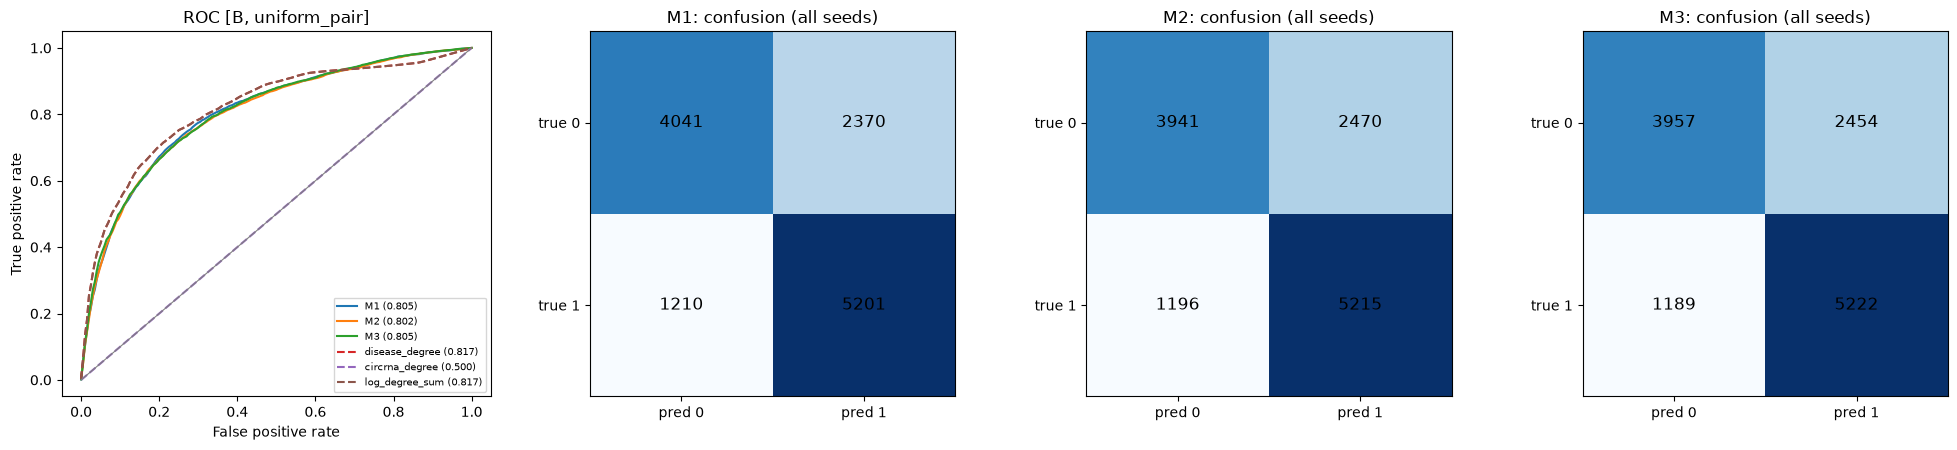

In [16]:
# 10_protocol_ladder - Cell 7: run B report
P_B = pd.concat([pd.read_csv(f) for m in ("M1", "M2", "M3") for f in sorted((OUT / "pred_B").glob(f"pred_{m}_seed*_fold*.csv"))], ignore_index=True)
print("B predictions:", len(P_B), "rows | validation-chosen thresholds:", P_B.groupby(["model", "seed", "fold"])["threshold"].first().describe().round(2).to_dict())
B_tab, B_seed = report(P_B, ["M1", "M2", "M3"], tag="B", scheme="uniform_pair")

## Cell 8: three follow-up checks

In [17]:
# 10_protocol_ladder - Cell 8: run B follow-up - (a) popularity rule with the same validation-chosen threshold, (b) paired bootstrap, (c) AUROC inside disease-degree strata
from circmtl import ladder as L
nD = gd.N["disease"]

# (a) disease training degree as the score, threshold chosen on the validation pairs, applied to test: same protocol as the models
rows = []
for s in range(3):
    for k in range(5):
        fd = gd.load_fold(s, k); z = np.load(OUT / "frozen_B" / f"negB_seed{s}_fold{k}.npz")
        dd = np.bincount(fd["disease_train"][:, 1], minlength=nD).astype(float)
        vp, vn = fd["disease_val"], z["neg_val"]
        thr, _ = L.best_f1_threshold(np.r_[np.ones(len(vp)), np.zeros(len(vn))], np.r_[dd[vp[:, 1]], dd[vn[:, 1]]])
        sp, sn = dd[fd["disease_test"][:, 1]], dd[z["neg_test"][:, 1]]
        rows.append({"seed": s, "TP": int((sp > thr).sum()), "FN": int((sp <= thr).sum()), "FP": int((sn > thr).sum()), "TN": int((sn <= thr).sum())})
pop = pd.DataFrame(rows).groupby("seed").sum()
tp, fn, fp, tn = (pop[c].to_numpy() for c in ("TP", "FN", "FP", "TN"))
popm = pd.DataFrame({"Accuracy": (tp + tn) / (tp + fn + fp + tn), "Precision": tp / (tp + fp), "Recall": tp / (tp + fn), "Specificity": tn / (tn + fp),
                     "F1": 2 * tp / (2 * tp + fp + fn), "MCC": [mcc_from(*v) for v in zip(tp, tn, fp, fn)]})
print("(a) disease_degree as a classifier, threshold chosen on validation (mean over seeds):")
print(popm.mean().round(3).to_string(), "\n")

# (b) paired bootstrap over host groups: models and the popularity rule on identical test pairs
W = P_B.pivot_table(index=["seed", "fold", "c", "t", "y"], columns="model", values="score_rank").reset_index()
assert W[["M1", "M2", "M3"]].notna().all().all(), "models are not aligned on the same test pairs"
W["disease_degree"] = baseline_scores(W, "disease_degree")
cols = ["M1", "M2", "M3", "disease_degree"]
yv, sd = W["y"].to_numpy(), W["seed"].to_numpy()
V = {c: W[c].to_numpy() for c in cols}
seed_ix = [np.flatnonzero(sd == s) for s in range(3)]
ug, gi = np.unique(gd.groups[W["c"].to_numpy()], return_inverse=True)
auc = lambda c, w=None: float(np.mean([roc_auc_score(yv[ix], V[c][ix], sample_weight=None if w is None else w[ix]) for ix in seed_ix]))
point = {c: auc(c) for c in cols}
rb, boots = np.random.default_rng(0), {c: [] for c in cols}
for _ in range(1000):
    w = np.bincount(rb.integers(0, len(ug), len(ug)), minlength=len(ug))[gi].astype(float)
    for c in cols: boots[c].append(auc(c, w))
boots = {c: np.array(v) for c, v in boots.items()}
print("(b) paired bootstrap over host groups (1000 resamples), AUROC difference [95% CI]:")
for a, b in (("M3", "M1"), ("M2", "M1"), ("M3", "M2"), ("M1", "disease_degree"), ("M2", "disease_degree"), ("M3", "disease_degree")):
    d = boots[a] - boots[b]
    print(f"   {a} - {b:14s} {point[a] - point[b]:+.4f} [{np.percentile(d, 2.5):+.4f}, {np.percentile(d, 97.5):+.4f}]")

# (c) AUROC inside disease-degree strata: positives and negatives with similar disease popularity
degp = np.zeros(len(W))
for (s, k), ix in W.groupby(["seed", "fold"]).indices.items():
    dd = np.bincount(gd.load_fold(s, k)["disease_train"][:, 1], minlength=nD)
    degp[ix] = dd[W["t"].to_numpy()[ix]]
rows = []
for lo, hi in ((0, 0), (1, 4), (5, 19), (20, 49), (50, 10**9)):
    m = (degp >= lo) & (degp <= hi)
    npos, nneg = int(yv[m].sum()), int((1 - yv[m]).sum())
    r = {"disease training degree": f"{lo}" if lo == hi else (f"{lo}+" if hi > 10**8 else f"{lo}-{hi}"), "test positives": npos, "test negatives": nneg}
    for c in cols:
        a = [roc_auc_score(yv[ix][m[ix]], V[c][ix][m[ix]]) for ix in seed_ix if 0 < yv[ix][m[ix]].sum() < m[ix].sum()] if min(npos, nneg) >= 30 else []
        r[c] = f"{np.mean(a):.3f}" if a else "n/a"
    rows.append(r)
print("\n(c) AUROC within disease-degree strata (mean over seeds; n/a if fewer than 30 pairs of either class):")
print(pd.DataFrame(rows).to_string(index=False))

(a) disease_degree as a classifier, threshold chosen on validation (mean over seeds):
Accuracy       0.727
Precision      0.687
Recall         0.836
Specificity    0.618
F1             0.754
MCC            0.466 

(b) paired bootstrap over host groups (1000 resamples), AUROC difference [95% CI]:
   M3 - M1             -0.0003 [-0.0048, +0.0042]
   M2 - M1             -0.0033 [-0.0072, +0.0009]
   M3 - M2             +0.0030 [-0.0005, +0.0066]
   M1 - disease_degree -0.0119 [-0.0178, -0.0058]
   M2 - disease_degree -0.0152 [-0.0211, -0.0097]
   M3 - disease_degree -0.0122 [-0.0173, -0.0072]

(c) AUROC within disease-degree strata (mean over seeds; n/a if fewer than 30 pairs of either class):
disease training degree  test positives  test negatives    M1    M2    M3 disease_degree
                      0             285             865 0.498 0.485 0.482          0.500
                    1-4             945            3406 0.650 0.641 0.641          0.690
                   5-19          

## Cell 9: runs A and C

In [18]:
# 10_protocol_ladder - Cell 9: runs A and C, step 3a - pair-level folds (10 seeds x 5), frozen negatives, leak and masking assertions, baseline floors (no training)
import importlib
from circmtl import ladder as L
importlib.reload(L)                                            # pick up the pair-level functions added to ladder.py
FP = OUT / "frozen_pair"; FP.mkdir(exist_ok=True)
nC, nD = gd.N["circRNA"], gd.N["disease"]
NAMES = ["disease_degree", "circrna_degree", "circrna_inverse_degree", "log_degree_sum", "kernel_circ", "kernel_dis", "kernel_both"]
SCHEMES = (("degree_matched", "A"), ("uniform_pair", "C"), ("uniform_test_circ", "C2"))
store, warm = {}, []
for s in range(10):
    for k in range(5):
        fd = L.pair_level_fold(gd, s, k)
        Y = L.label_matrix(fd["disease_train"], nC, nD)
        L.check_masked_matrix(gd, fd, Y)                       # kernels/degrees below use training pairs only
        KS = L.kernel_scores(Y)
        deg_d, deg_c = Y.sum(0), Y.sum(1)
        warm.append(np.mean(deg_c[fd["disease_test"][:, 0]] > 0))
        for scheme, tag in SCHEMES:
            nv, nt = L.frozen_negatives_pair(gd, fd, s, k, scheme)
            L.check_fold_pair(gd, fd, nv, nt, scheme)          # raises AssertionError on any leak
            np.savez(FP / f"neg{tag}_seed{s}_fold{k}.npz", neg_val=nv, neg_test=nt)
            pos = fd["disease_test"]; pr = np.vstack([pos, nt])
            y = np.r_[np.ones(len(pos)), np.zeros(len(nt))]
            sc = {"disease_degree": deg_d[pr[:, 1]], "circrna_degree": deg_c[pr[:, 0]], "circrna_inverse_degree": -deg_c[pr[:, 0]],
                  "log_degree_sum": np.log1p(deg_d[pr[:, 1]]) + np.log1p(deg_c[pr[:, 0]]),
                  **{n: S[pr[:, 0], pr[:, 1]] for n, S in KS.items()}}
            d = store.setdefault((tag, s), {"y": []} | {n: [] for n in NAMES})
            d["y"].append(y)
            for n in NAMES:
                d[n].append(pd.Series(sc[n]).rank(pct=True).to_numpy())          # rank within fold, then pool within seed
print("all pair-level folds passed the leak and masking assertions (10 seeds x 5 folds x 3 negative schemes)\n")
print(f"share of test positives whose circRNA has >= 1 training pair ('warm'): {np.mean(warm):.3f}  (the rest behave like new circRNAs)\n")
rows = {}
for tag in ("A", "C", "C2"):
    for n in NAMES:
        a = [roc_auc_score(np.concatenate(store[(tag, s)]["y"]), np.concatenate(store[(tag, s)][n])) for s in range(10)]
        rows.setdefault(n, {})[f"run {tag}"] = f"{np.mean(a):.3f} ({min(a):.3f}-{max(a):.3f})"
print("baseline AUROC, pair-level folds (mean over 10 seeds, range); A = degree-matched, C = uniform pair (all circRNAs), C2 = uniform pair (circRNAs of the evaluated set)")
print(pd.DataFrame(rows).T.to_string())
pd.DataFrame(rows).T.to_csv(FP / "pair_level_baseline_floors.csv")

all pair-level folds passed the leak and masking assertions (10 seeds x 5 folds x 3 negative schemes)

share of test positives whose circRNA has >= 1 training pair ('warm'): 0.318  (the rest behave like new circRNAs)

baseline AUROC, pair-level folds (mean over 10 seeds, range); A = degree-matched, C = uniform pair (all circRNAs), C2 = uniform pair (circRNAs of the evaluated set)
                                      run A                run C               run C2
disease_degree          0.503 (0.493-0.508)  0.822 (0.814-0.829)  0.823 (0.817-0.830)
circrna_degree          0.500 (0.500-0.500)  0.347 (0.340-0.354)  0.526 (0.520-0.534)
circrna_inverse_degree  0.500 (0.500-0.500)  0.653 (0.646-0.660)  0.474 (0.466-0.480)
log_degree_sum          0.498 (0.490-0.503)  0.774 (0.764-0.781)  0.814 (0.810-0.818)
kernel_circ             0.504 (0.494-0.509)  0.822 (0.814-0.829)  0.819 (0.813-0.827)
kernel_dis              0.500 (0.500-0.501)  0.329 (0.323-0.336)  0.524 (0.518-0.533)
kernel_both    

## Cell 10: logistic regression on the two training degrees

In [19]:
# 10_protocol_ladder - Cell 10: strongest shortcut-only reference - logistic regression on the two training degrees, fitted on the VALIDATION pairs, scored on the TEST pairs (no neural model, no test labels)
from sklearn.linear_model import LogisticRegression
FP = OUT / "frozen_pair"
store10 = {}
for s in range(10):
    for k in range(5):
        fd = L.pair_level_fold(gd, s, k)
        Y = L.label_matrix(fd["disease_train"], gd.N["circRNA"], gd.N["disease"])
        dd, dc = Y.sum(0), Y.sum(1)                                              # training degrees only
        feats = lambda pos, neg: (np.c_[np.log1p(dd[np.vstack([pos, neg])[:, 1]]), np.log1p(dc[np.vstack([pos, neg])[:, 0]])],
                                  np.r_[np.ones(len(pos)), np.zeros(len(neg))])
        for tag in ("A", "C", "C2"):
            z = np.load(FP / f"neg{tag}_seed{s}_fold{k}.npz")
            Xv, yv_ = feats(fd["disease_val"], z["neg_val"])                     # fit on validation pairs and validation negatives
            Xt, yt_ = feats(fd["disease_test"], z["neg_test"])                   # score the test pairs
            clf = LogisticRegression(C=1.0).fit(Xv, yv_)
            d = store10.setdefault((tag, s), {"y": [], "sc": [], "coef": []})
            d["y"].append(yt_); d["sc"].append(pd.Series(clf.decision_function(Xt)).rank(pct=True).to_numpy()); d["coef"].append(clf.coef_[0])
rows = []
for tag in ("A", "C", "C2"):
    a = [roc_auc_score(np.concatenate(store10[(tag, s)]["y"]), np.concatenate(store10[(tag, s)]["sc"])) for s in range(10)]
    co = np.mean([c for s in range(10) for c in store10[(tag, s)]["coef"]], axis=0)
    rows.append({"run": tag, "shortcut_logit AUROC": f"{np.mean(a):.3f} ({min(a):.3f}-{max(a):.3f})",
                 "coef log1p(disease degree)": f"{co[0]:+.2f}", "coef log1p(circRNA degree)": f"{co[1]:+.2f}"})
print("shortcut_logit: logistic regression on [log1p disease training degree, log1p circRNA training degree], pair-level folds, mean over 10 seeds (range)")
print(pd.DataFrame(rows).to_string(index=False))
pd.DataFrame(rows).to_csv(FP / "pair_level_shortcut_logit.csv", index=False)

shortcut_logit: logistic regression on [log1p disease training degree, log1p circRNA training degree], pair-level folds, mean over 10 seeds (range)
run shortcut_logit AUROC coef log1p(disease degree) coef log1p(circRNA degree)
  A  0.503 (0.493-0.519)                      -0.01                      -0.00
  C  0.831 (0.824-0.838)                      +1.06                      -0.66
 C2  0.824 (0.818-0.830)                      +1.06                      +0.20


## Cell 12: training for A

In [22]:
# 10_protocol_ladder - Cell 12: pair-level runs A, C and C2 (set RUN; resumable; a finished run is locked)
import importlib
from circmtl import ladder as L
importlib.reload(L)
RUN = "A"                                                    # "A", then "C", then "C2": one run per execution of this cell
SCHEME = {"A": "degree_matched", "C": "uniform_pair", "C2": "uniform_test_circ"}[RUN]
OUTR = OUT / f"pred_{RUN}"; OUTR.mkdir(exist_ok=True)
assert not (OUTR / "DONE.txt").exists(), f"run {RUN} is finished and locked; a rerun is only allowed to fix a failed assertion (log it in run_log)"
MODELS_R, AUX_W, nD = ["M1", "M2", "M3"], [0.1, 0.5, 1.0], gd.N["disease"]
t0, log = time.time(), []
for s in range(10):
    for k in range(5):
        todo = [m for m in MODELS_R if not (OUTR / f"pred_{m}_seed{s}_fold{k}.csv").exists()]
        if not todo:
            continue                                                         # resume: finished files are kept
        fd = L.pair_level_fold(gd, s, k)
        z = np.load(OUT / "frozen_pair" / f"neg{RUN}_seed{s}_fold{k}.npz"); neg_val, neg_test = z["neg_val"], z["neg_test"]
        L.check_fold_pair(gd, fd, neg_val, neg_test, SCHEME)                 # leak assertions before every fit
        L.check_masked_matrix(gd, fd, L.label_matrix(fd["disease_train"], gd.N["circRNA"], nD))
        tcodes = L.codes(fd["disease_train"][:, 0], fd["disease_train"][:, 1], nD)

        def neg_fn(sup, rng, fd=fd, tcodes=tcodes):                          # training negatives: exclude TRAINING positives only
            if RUN == "A":
                neg = L.degree_train_negatives(nD, sup, fd["disease_train"], tcodes, rng, k=TRAIN["neg_k"])
            else:
                neg = L.uniform_train_negatives(nD, sup, fd["train"], tcodes, rng, k=TRAIN["neg_k"])
            L.check_train_negatives(nD, neg, fd)
            return neg

        for m in todo:
            weights = AUX_W if any(r in HEADS[m] for r in AUX) else [None]
            cands = []
            for w in weights:
                model, x, hist, best, vs = train_one_l(fd, m, aux_w=(w or 0.0), seed=s, disease_neg_fn=neg_fn, val_neg=neg_val)
                cands.append((best["auc"], w, model, x, best["epoch"], vs))
            val_auc, w, model, x, ep, (vsp, vsn) = max(cands, key=lambda c: c[0])           # chosen on VALIDATION only
            thr, vf1 = L.best_f1_threshold(np.r_[np.ones(len(vsp)), np.zeros(len(vsn))], np.r_[vsp, vsn])
            predict_l(model, x, fd, m, neg_test, scheme=SCHEME).assign(model=m, seed=s, fold=k, aux_w=w, best_epoch=ep, val_auc=val_auc,
                                                                      threshold=thr, val_f1=vf1).to_csv(OUTR / f"pred_{m}_seed{s}_fold{k}.csv", index=False)
            log.append({"model": m, "seed": s, "fold": k, "aux_w": w, "best_epoch": ep, "val_auc": round(val_auc, 3), "thr": round(thr, 3)})
            print(f"  {RUN} {m:3s} seed {s} fold {k} | w {w} | best epoch {ep:3d} | val {val_auc:.3f} | thr {thr:+.2f} | {time.time() - t0:6.0f}s")
if log:
    pd.DataFrame(log).to_csv(OUTR / "run_log.csv", mode="a", index=False, header=not (OUTR / "run_log.csv").exists())
n_files = len(list(OUTR.glob("pred_*_seed*_fold*.csv")))
if n_files == 150:
    (OUTR / "DONE.txt").write_text(f"run {RUN} complete: 150 prediction files, written {time.strftime('%Y-%m-%d %H:%M')}\n")
print(f"run {RUN}: {n_files} of 150 prediction files | {time.time() - t0:.0f}s this session")

  A M1  seed 0 fold 0 | w None | best epoch  57 | val 0.565 | thr -3.67 |      3s
  A M2  seed 0 fold 0 | w None | best epoch 101 | val 0.569 | thr -4.13 |      7s
  A M3  seed 0 fold 0 | w 1.0 | best epoch  45 | val 0.568 | thr -0.66 |     31s
  A M1  seed 0 fold 1 | w None | best epoch  23 | val 0.554 | thr -0.74 |     33s
  A M2  seed 0 fold 1 | w None | best epoch  53 | val 0.561 | thr -1.03 |     35s
  A M3  seed 0 fold 1 | w 0.1 | best epoch  81 | val 0.570 | thr -1.82 |     68s
  A M1  seed 0 fold 2 | w None | best epoch  92 | val 0.552 | thr -4.67 |     71s
  A M2  seed 0 fold 2 | w None | best epoch  72 | val 0.550 | thr -3.56 |     75s
  A M3  seed 0 fold 2 | w 0.5 | best epoch  52 | val 0.572 | thr -1.22 |     96s
  A M1  seed 0 fold 3 | w None | best epoch 138 | val 0.595 | thr -3.24 |    100s
  A M2  seed 0 fold 3 | w None | best epoch 121 | val 0.596 | thr -1.63 |    105s
  A M3  seed 0 fold 3 | w 0.5 | best epoch  78 | val 0.617 | thr -2.17 |    132s
  A M1  seed 0 fold 

## Cell 13: pair-level report A

run A: {'M1': 50, 'M2': 50, 'M3': 50} seed-folds per model (expect 50 each)
[A] disease task | degree_matched negatives | threshold = chosen on validation, per fold | mean over seeds (range)
                                      AUROC                 AUPR             Accuracy            Precision               Recall          Specificity                   F1                   MCC
M1                      0.539 (0.520-0.549)  0.531 (0.517-0.542)  0.503 (0.499-0.507)  0.501 (0.500-0.503)  0.979 (0.952-0.995)  0.026 (0.005-0.061)  0.663 (0.656-0.668)  0.018 (-0.003-0.047)
M2                      0.543 (0.527-0.567)  0.533 (0.515-0.556)  0.504 (0.500-0.508)  0.502 (0.500-0.504)  0.969 (0.938-0.986)  0.039 (0.019-0.071)  0.661 (0.654-0.665)   0.022 (0.000-0.037)
M3                      0.546 (0.532-0.561)  0.536 (0.518-0.550)  0.505 (0.500-0.510)  0.503 (0.500-0.505)  0.976 (0.957-0.999)  0.034 (0.004-0.056)  0.663 (0.660-0.667)   0.029 (0.000-0.051)
disease_degree          0.503 (0.493-0.50

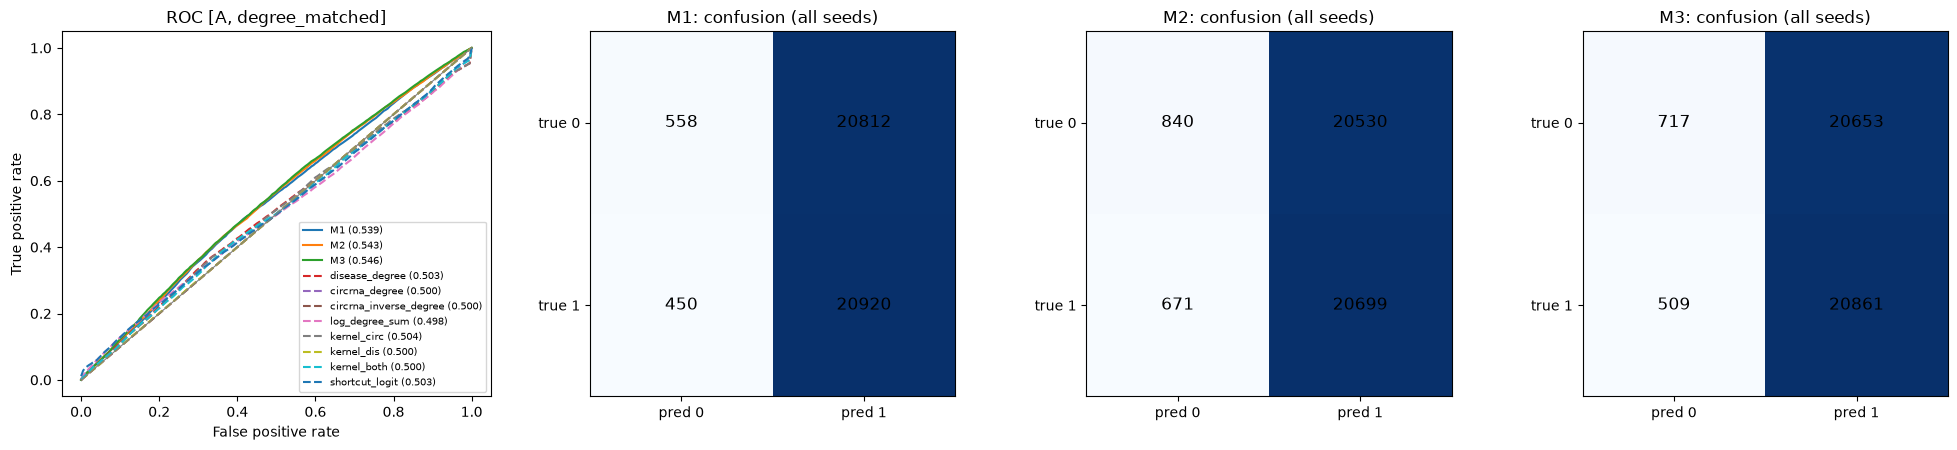


AUROC by circRNA status [A, degree_matched] (mean over seeds):
                          stratum   pos   neg    M1    M2    M3 disease_degree shortcut_logit
warm (circRNA has training pairs)  6800  6800 0.539 0.554 0.555          0.555          0.483
          cold (circRNA has none) 14570 14570 0.539 0.537 0.542          0.478          0.511


In [31]:
# 10_protocol_ladder - Cell 13: pair-level report for the run set in RUN: metrics, baselines from TRAINING pairs only, and AUROC split by whether the circRNA has training pairs
from sklearn.linear_model import LogisticRegression
from circmtl import ladder as L
RUN = "A"                                                    # same value as in Cell 12
SCHEME = {"A": "degree_matched", "C": "uniform_pair", "C2": "uniform_test_circ"}[RUN]
nC, nD = gd.N["circRNA"], gd.N["disease"]
if "_bs_host" not in globals():
    _bs_host = baseline_scores                                # the host-gene version from Cell 1
PAIR = {"on": True, "tag": RUN}

def baseline_scores(d, kind):
    if not PAIR["on"]:
        return _bs_host(d, kind)
    out = np.zeros(len(d))
    for (s, k), ix in d.groupby(["seed", "fold"]).indices.items():
        fd = L.pair_level_fold(gd, int(s), int(k))
        Y = L.label_matrix(fd["disease_train"], nC, nD); dd, dc = Y.sum(0), Y.sum(1)
        c, t = d["c"].to_numpy()[ix], d["t"].to_numpy()[ix]
        if kind == "disease_degree":          sc = dd[t]
        elif kind == "circrna_degree":        sc = dc[c]
        elif kind == "circrna_inverse_degree": sc = -dc[c]
        elif kind == "log_degree_sum":        sc = np.log1p(dd[t]) + np.log1p(dc[c])
        elif kind.startswith("kernel_"):      sc = L.kernel_scores(Y)[kind][c, t]
        elif kind == "shortcut_logit":
            z = np.load(OUT / "frozen_pair" / f"neg{PAIR['tag']}_seed{int(s)}_fold{int(k)}.npz")
            pv = np.vstack([fd["disease_val"], z["neg_val"]]); yv_ = np.r_[np.ones(len(fd["disease_val"])), np.zeros(len(z["neg_val"]))]
            clf = LogisticRegression(C=1.0).fit(np.c_[np.log1p(dd[pv[:, 1]]), np.log1p(dc[pv[:, 0]])], yv_)    # fitted on validation only
            sc = clf.decision_function(np.c_[np.log1p(dd[t]), np.log1p(dc[c])])
        else:
            raise ValueError(kind)
        out[ix] = sc
    return out

P_R = pd.concat([pd.read_csv(f) for m in ("M1", "M2", "M3") for f in sorted((OUT / f"pred_{RUN}").glob(f"pred_{m}_seed*_fold*.csv"))], ignore_index=True)
print(f"run {RUN}: {P_R.groupby('model')[['seed', 'fold']].apply(lambda g: len(g.drop_duplicates()))[['M1', 'M2', 'M3']].to_dict()} seed-folds per model (expect 50 each)")
BL = ("disease_degree", "circrna_degree", "circrna_inverse_degree", "log_degree_sum", "kernel_circ", "kernel_dis", "kernel_both", "shortcut_logit")
R_tab, R_seed = report(P_R, ["M1", "M2", "M3"], tag=RUN, scheme=SCHEME, baselines=BL)

# AUROC split by whether the pair's circRNA has >= 1 training pair (removes the held-out artifact inside each stratum)
warm = np.zeros(len(P_R), bool)
for (s, k), ix in P_R.groupby(["seed", "fold"]).indices.items():
    dc = np.bincount(L.pair_level_fold(gd, int(s), int(k))["disease_train"][:, 0], minlength=nC)
    warm[ix] = dc[P_R["c"].to_numpy()[ix]] > 0
base = P_R[P_R["model"] == "M1"][["seed", "fold", "c", "t", "y"]].reset_index(drop=True)
warm_b = warm[(P_R["model"] == "M1").to_numpy()]
comp = {"disease_degree": baseline_scores(base, "disease_degree"), "shortcut_logit": baseline_scores(base, "shortcut_logit")}
rows = []
for name, msk in (("warm (circRNA has training pairs)", True), ("cold (circRNA has none)", False)):
    r = {"stratum": name}
    sel_b = warm_b == msk
    r["pos"], r["neg"] = int(base["y"][sel_b].sum()), int((1 - base["y"][sel_b]).sum())
    for m in ("M1", "M2", "M3"):
        g = P_R[(P_R["model"] == m).to_numpy() & (warm == msk)]
        a = [roc_auc_score(x["y"], x["score_rank"]) for _, x in g.groupby("seed") if 0 < x["y"].sum() < len(x)]
        r[m] = f"{np.mean(a):.3f}" if a else "n/a"
    for cname, v in comp.items():
        a = [roc_auc_score(base["y"][sel_b & (base["seed"] == s).to_numpy()], v[sel_b & (base["seed"] == s).to_numpy()]) for s in range(10)
             if 0 < base["y"][sel_b & (base["seed"] == s).to_numpy()].sum() < (sel_b & (base["seed"] == s).to_numpy()).sum()]
        r[cname] = f"{np.mean(a):.3f}" if a else "n/a"
    rows.append(r)
print(f"\nAUROC by circRNA status [{RUN}, {SCHEME}] (mean over seeds):")
print(pd.DataFrame(rows).to_string(index=False))
PAIR["on"] = False                                           # restore the host-gene baselines for earlier cells

## Cell 14: paired bootstrap A

In [32]:
# 10_protocol_ladder - Cell 14: paired bootstrap over host groups for one pair-level run (run Cell 13 first, with the same RUN)
N_BOOT = 1000
PAIR["on"], PAIR["tag"] = True, RUN
W = P_R.pivot_table(index=["seed", "fold", "c", "t", "y"], columns="model", values="score_rank").reset_index()
assert W[["M1", "M2", "M3"]].notna().all().all(), "models are not aligned on the same test pairs"
for b in ("disease_degree", "shortcut_logit"):
    v = baseline_scores(W, b)                                               # from TRAINING pairs only
    W[b] = pd.Series(v).groupby([W["seed"], W["fold"]]).rank(pct=True).to_numpy()
PAIR["on"] = False
cols = ["M1", "M2", "M3", "disease_degree", "shortcut_logit"]
yv, sd = W["y"].to_numpy(), W["seed"].to_numpy()
V = {c: W[c].to_numpy() for c in cols}
seed_ix = [np.flatnonzero(sd == s) for s in sorted(W["seed"].unique())]
ug, gi = np.unique(gd.groups[W["c"].to_numpy()], return_inverse=True)
auc = lambda c, w=None: float(np.mean([roc_auc_score(yv[ix], V[c][ix], sample_weight=None if w is None else w[ix]) for ix in seed_ix]))
point = {c: auc(c) for c in cols}
rb, boots = np.random.default_rng(0), {c: [] for c in cols}
for _ in range(N_BOOT):
    w = np.bincount(rb.integers(0, len(ug), len(ug)), minlength=len(ug))[gi].astype(float)
    for c in cols:
        boots[c].append(auc(c, w))
boots = {c: np.array(v) for c, v in boots.items()}
print(f"run {RUN}: paired bootstrap over host groups ({N_BOOT} resamples), AUROC difference [95% CI]:")
for a, b in (("M3", "M1"), ("M2", "M1"), ("M3", "M2"), ("M1", "disease_degree"), ("M2", "disease_degree"), ("M3", "disease_degree"),
             ("M1", "shortcut_logit"), ("M2", "shortcut_logit"), ("M3", "shortcut_logit")):
    d = boots[a] - boots[b]
    print(f"   {a} - {b:15s} {point[a] - point[b]:+.4f} [{np.percentile(d, 2.5):+.4f}, {np.percentile(d, 97.5):+.4f}]")

run A: paired bootstrap over host groups (1000 resamples), AUROC difference [95% CI]:
   M3 - M1              +0.0075 [+0.0019, +0.0132]
   M2 - M1              +0.0040 [-0.0011, +0.0090]
   M3 - M2              +0.0035 [-0.0009, +0.0087]
   M1 - disease_degree  +0.0351 [+0.0177, +0.0520]
   M2 - disease_degree  +0.0391 [+0.0226, +0.0559]
   M3 - disease_degree  +0.0426 [+0.0267, +0.0588]
   M1 - shortcut_logit  +0.0357 [+0.0255, +0.0462]
   M2 - shortcut_logit  +0.0397 [+0.0293, +0.0505]
   M3 - shortcut_logit  +0.0432 [+0.0323, +0.0543]


## Cell 15: training for C

In [24]:
# 10_protocol_ladder - Cell 12: pair-level runs A, C and C2 (set RUN; resumable; a finished run is locked)
import importlib
from circmtl import ladder as L
importlib.reload(L)
RUN = "C"                                                    # "A", then "C", then "C2": one run per execution of this cell
SCHEME = {"A": "degree_matched", "C": "uniform_pair", "C2": "uniform_test_circ"}[RUN]
OUTR = OUT / f"pred_{RUN}"; OUTR.mkdir(exist_ok=True)
assert not (OUTR / "DONE.txt").exists(), f"run {RUN} is finished and locked; a rerun is only allowed to fix a failed assertion (log it in run_log)"
MODELS_R, AUX_W, nD = ["M1", "M2", "M3"], [0.1, 0.5, 1.0], gd.N["disease"]
t0, log = time.time(), []
for s in range(10):
    for k in range(5):
        todo = [m for m in MODELS_R if not (OUTR / f"pred_{m}_seed{s}_fold{k}.csv").exists()]
        if not todo:
            continue                                                         # resume: finished files are kept
        fd = L.pair_level_fold(gd, s, k)
        z = np.load(OUT / "frozen_pair" / f"neg{RUN}_seed{s}_fold{k}.npz"); neg_val, neg_test = z["neg_val"], z["neg_test"]
        L.check_fold_pair(gd, fd, neg_val, neg_test, SCHEME)                 # leak assertions before every fit
        L.check_masked_matrix(gd, fd, L.label_matrix(fd["disease_train"], gd.N["circRNA"], nD))
        tcodes = L.codes(fd["disease_train"][:, 0], fd["disease_train"][:, 1], nD)

        def neg_fn(sup, rng, fd=fd, tcodes=tcodes):                          # training negatives: exclude TRAINING positives only
            if RUN == "A":
                neg = L.degree_train_negatives(nD, sup, fd["disease_train"], tcodes, rng, k=TRAIN["neg_k"])
            else:
                neg = L.uniform_train_negatives(nD, sup, fd["train"], tcodes, rng, k=TRAIN["neg_k"])
            L.check_train_negatives(nD, neg, fd)
            return neg

        for m in todo:
            weights = AUX_W if any(r in HEADS[m] for r in AUX) else [None]
            cands = []
            for w in weights:
                model, x, hist, best, vs = train_one_l(fd, m, aux_w=(w or 0.0), seed=s, disease_neg_fn=neg_fn, val_neg=neg_val)
                cands.append((best["auc"], w, model, x, best["epoch"], vs))
            val_auc, w, model, x, ep, (vsp, vsn) = max(cands, key=lambda c: c[0])           # chosen on VALIDATION only
            thr, vf1 = L.best_f1_threshold(np.r_[np.ones(len(vsp)), np.zeros(len(vsn))], np.r_[vsp, vsn])
            predict_l(model, x, fd, m, neg_test, scheme=SCHEME).assign(model=m, seed=s, fold=k, aux_w=w, best_epoch=ep, val_auc=val_auc,
                                                                      threshold=thr, val_f1=vf1).to_csv(OUTR / f"pred_{m}_seed{s}_fold{k}.csv", index=False)
            log.append({"model": m, "seed": s, "fold": k, "aux_w": w, "best_epoch": ep, "val_auc": round(val_auc, 3), "thr": round(thr, 3)})
            print(f"  {RUN} {m:3s} seed {s} fold {k} | w {w} | best epoch {ep:3d} | val {val_auc:.3f} | thr {thr:+.2f} | {time.time() - t0:6.0f}s")
if log:
    pd.DataFrame(log).to_csv(OUTR / "run_log.csv", mode="a", index=False, header=not (OUTR / "run_log.csv").exists())
n_files = len(list(OUTR.glob("pred_*_seed*_fold*.csv")))
if n_files == 150:
    (OUTR / "DONE.txt").write_text(f"run {RUN} complete: 150 prediction files, written {time.strftime('%Y-%m-%d %H:%M')}\n")
print(f"run {RUN}: {n_files} of 150 prediction files | {time.time() - t0:.0f}s this session")

  C M1  seed 0 fold 0 | w None | best epoch  96 | val 0.862 | thr -1.15 |      4s
  C M2  seed 0 fold 0 | w None | best epoch 136 | val 0.863 | thr -1.02 |      9s
  C M3  seed 0 fold 0 | w 1.0 | best epoch 115 | val 0.867 | thr -1.59 |     47s
  C M1  seed 0 fold 1 | w None | best epoch 117 | val 0.843 | thr -1.48 |     51s
  C M2  seed 0 fold 1 | w None | best epoch 120 | val 0.839 | thr -1.67 |     55s
  C M3  seed 0 fold 1 | w 0.1 | best epoch 162 | val 0.840 | thr -1.44 |     99s
  C M1  seed 0 fold 2 | w None | best epoch 119 | val 0.856 | thr -1.36 |    103s
  C M2  seed 0 fold 2 | w None | best epoch  85 | val 0.854 | thr -0.70 |    106s
  C M3  seed 0 fold 2 | w 0.1 | best epoch  84 | val 0.857 | thr -0.85 |    143s
  C M1  seed 0 fold 3 | w None | best epoch  85 | val 0.867 | thr -1.14 |    146s
  C M2  seed 0 fold 3 | w None | best epoch 113 | val 0.866 | thr -1.84 |    150s
  C M3  seed 0 fold 3 | w 1.0 | best epoch  88 | val 0.869 | thr -0.46 |    187s
  C M1  seed 0 fold 

## Cell 16: pair-level report C

run C: {'M1': 50, 'M2': 50, 'M3': 50} seed-folds per model (expect 50 each)
[C] disease task | uniform_pair negatives | threshold = chosen on validation, per fold | mean over seeds (range)
                                      AUROC                 AUPR             Accuracy            Precision               Recall          Specificity                   F1                  MCC
M1                      0.864 (0.857-0.871)  0.856 (0.837-0.867)  0.779 (0.766-0.788)  0.750 (0.730-0.769)  0.839 (0.814-0.862)  0.720 (0.681-0.755)  0.792 (0.784-0.802)  0.563 (0.540-0.580)
M2                      0.863 (0.857-0.875)  0.857 (0.845-0.868)  0.779 (0.767-0.791)  0.747 (0.725-0.775)  0.844 (0.819-0.874)  0.713 (0.669-0.763)  0.792 (0.783-0.801)  0.563 (0.540-0.583)
M3                      0.864 (0.854-0.871)  0.860 (0.846-0.869)  0.779 (0.766-0.791)  0.750 (0.722-0.769)  0.838 (0.817-0.864)  0.721 (0.667-0.754)  0.791 (0.784-0.801)  0.563 (0.542-0.584)
disease_degree          0.822 (0.814-0.829)  0.

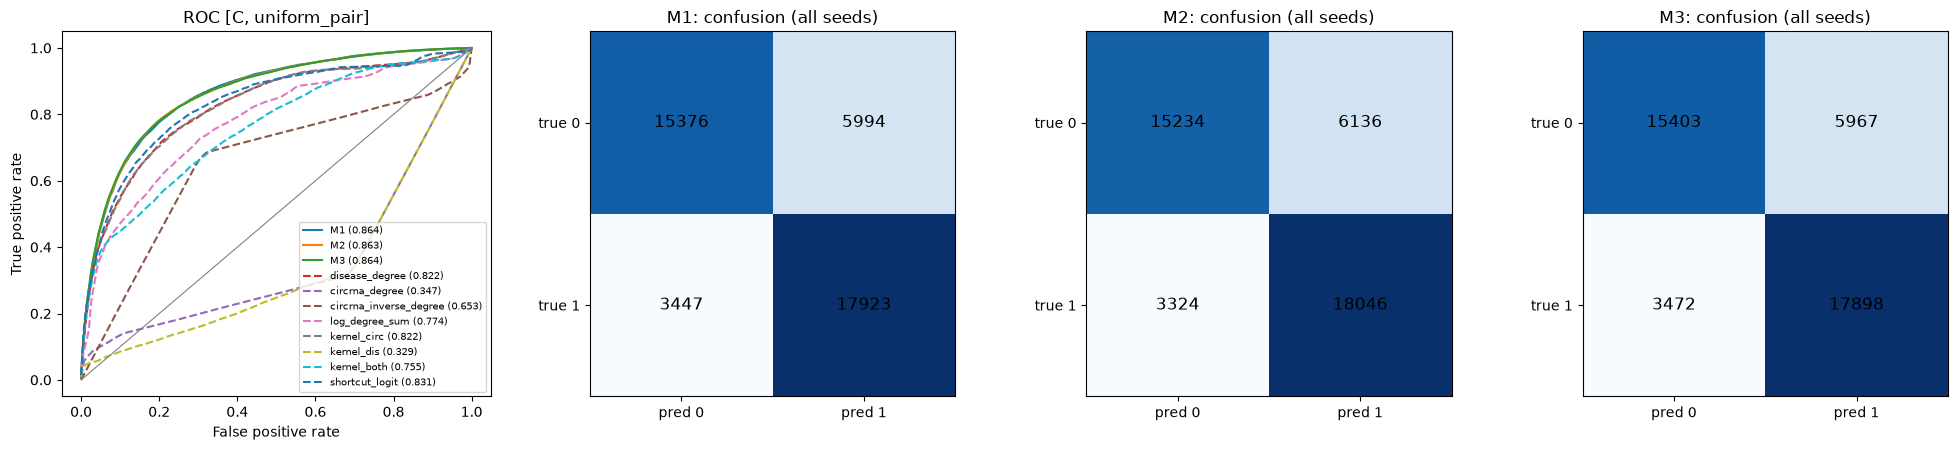


AUROC by circRNA status [C, uniform_pair] (mean over seeds):
                          stratum   pos   neg    M1    M2    M3 disease_degree shortcut_logit
warm (circRNA has training pairs)  6800 14752 0.854 0.855 0.856          0.839          0.802
          cold (circRNA has none) 14570  6618 0.800 0.799 0.801          0.814          0.813


In [33]:
# 10_protocol_ladder - Cell 13: pair-level report for the run set in RUN: metrics, baselines from TRAINING pairs only, and AUROC split by whether the circRNA has training pairs
from sklearn.linear_model import LogisticRegression
from circmtl import ladder as L
RUN = "C"                                                    # same value as in Cell 12
SCHEME = {"A": "degree_matched", "C": "uniform_pair", "C2": "uniform_test_circ"}[RUN]
nC, nD = gd.N["circRNA"], gd.N["disease"]
if "_bs_host" not in globals():
    _bs_host = baseline_scores                                # the host-gene version from Cell 1
PAIR = {"on": True, "tag": RUN}

def baseline_scores(d, kind):
    if not PAIR["on"]:
        return _bs_host(d, kind)
    out = np.zeros(len(d))
    for (s, k), ix in d.groupby(["seed", "fold"]).indices.items():
        fd = L.pair_level_fold(gd, int(s), int(k))
        Y = L.label_matrix(fd["disease_train"], nC, nD); dd, dc = Y.sum(0), Y.sum(1)
        c, t = d["c"].to_numpy()[ix], d["t"].to_numpy()[ix]
        if kind == "disease_degree":          sc = dd[t]
        elif kind == "circrna_degree":        sc = dc[c]
        elif kind == "circrna_inverse_degree": sc = -dc[c]
        elif kind == "log_degree_sum":        sc = np.log1p(dd[t]) + np.log1p(dc[c])
        elif kind.startswith("kernel_"):      sc = L.kernel_scores(Y)[kind][c, t]
        elif kind == "shortcut_logit":
            z = np.load(OUT / "frozen_pair" / f"neg{PAIR['tag']}_seed{int(s)}_fold{int(k)}.npz")
            pv = np.vstack([fd["disease_val"], z["neg_val"]]); yv_ = np.r_[np.ones(len(fd["disease_val"])), np.zeros(len(z["neg_val"]))]
            clf = LogisticRegression(C=1.0).fit(np.c_[np.log1p(dd[pv[:, 1]]), np.log1p(dc[pv[:, 0]])], yv_)    # fitted on validation only
            sc = clf.decision_function(np.c_[np.log1p(dd[t]), np.log1p(dc[c])])
        else:
            raise ValueError(kind)
        out[ix] = sc
    return out

P_R = pd.concat([pd.read_csv(f) for m in ("M1", "M2", "M3") for f in sorted((OUT / f"pred_{RUN}").glob(f"pred_{m}_seed*_fold*.csv"))], ignore_index=True)
print(f"run {RUN}: {P_R.groupby('model')[['seed', 'fold']].apply(lambda g: len(g.drop_duplicates()))[['M1', 'M2', 'M3']].to_dict()} seed-folds per model (expect 50 each)")
BL = ("disease_degree", "circrna_degree", "circrna_inverse_degree", "log_degree_sum", "kernel_circ", "kernel_dis", "kernel_both", "shortcut_logit")
R_tab, R_seed = report(P_R, ["M1", "M2", "M3"], tag=RUN, scheme=SCHEME, baselines=BL)

# AUROC split by whether the pair's circRNA has >= 1 training pair (removes the held-out artifact inside each stratum)
warm = np.zeros(len(P_R), bool)
for (s, k), ix in P_R.groupby(["seed", "fold"]).indices.items():
    dc = np.bincount(L.pair_level_fold(gd, int(s), int(k))["disease_train"][:, 0], minlength=nC)
    warm[ix] = dc[P_R["c"].to_numpy()[ix]] > 0
base = P_R[P_R["model"] == "M1"][["seed", "fold", "c", "t", "y"]].reset_index(drop=True)
warm_b = warm[(P_R["model"] == "M1").to_numpy()]
comp = {"disease_degree": baseline_scores(base, "disease_degree"), "shortcut_logit": baseline_scores(base, "shortcut_logit")}
rows = []
for name, msk in (("warm (circRNA has training pairs)", True), ("cold (circRNA has none)", False)):
    r = {"stratum": name}
    sel_b = warm_b == msk
    r["pos"], r["neg"] = int(base["y"][sel_b].sum()), int((1 - base["y"][sel_b]).sum())
    for m in ("M1", "M2", "M3"):
        g = P_R[(P_R["model"] == m).to_numpy() & (warm == msk)]
        a = [roc_auc_score(x["y"], x["score_rank"]) for _, x in g.groupby("seed") if 0 < x["y"].sum() < len(x)]
        r[m] = f"{np.mean(a):.3f}" if a else "n/a"
    for cname, v in comp.items():
        a = [roc_auc_score(base["y"][sel_b & (base["seed"] == s).to_numpy()], v[sel_b & (base["seed"] == s).to_numpy()]) for s in range(10)
             if 0 < base["y"][sel_b & (base["seed"] == s).to_numpy()].sum() < (sel_b & (base["seed"] == s).to_numpy()).sum()]
        r[cname] = f"{np.mean(a):.3f}" if a else "n/a"
    rows.append(r)
print(f"\nAUROC by circRNA status [{RUN}, {SCHEME}] (mean over seeds):")
print(pd.DataFrame(rows).to_string(index=False))
PAIR["on"] = False                                           # restore the host-gene baselines for earlier cells

## Cell 17: paired bootstrap C

In [34]:
# 10_protocol_ladder - Cell 14: paired bootstrap over host groups for one pair-level run (run Cell 13 first, with the same RUN)
N_BOOT = 1000
RUN = "C"
PAIR["on"], PAIR["tag"] = True, RUN
W = P_R.pivot_table(index=["seed", "fold", "c", "t", "y"], columns="model", values="score_rank").reset_index()
assert W[["M1", "M2", "M3"]].notna().all().all(), "models are not aligned on the same test pairs"
for b in ("disease_degree", "shortcut_logit"):
    v = baseline_scores(W, b)                                               # from TRAINING pairs only
    W[b] = pd.Series(v).groupby([W["seed"], W["fold"]]).rank(pct=True).to_numpy()
PAIR["on"] = False
cols = ["M1", "M2", "M3", "disease_degree", "shortcut_logit"]
yv, sd = W["y"].to_numpy(), W["seed"].to_numpy()
V = {c: W[c].to_numpy() for c in cols}
seed_ix = [np.flatnonzero(sd == s) for s in sorted(W["seed"].unique())]
ug, gi = np.unique(gd.groups[W["c"].to_numpy()], return_inverse=True)
auc = lambda c, w=None: float(np.mean([roc_auc_score(yv[ix], V[c][ix], sample_weight=None if w is None else w[ix]) for ix in seed_ix]))
point = {c: auc(c) for c in cols}
rb, boots = np.random.default_rng(0), {c: [] for c in cols}
for _ in range(N_BOOT):
    w = np.bincount(rb.integers(0, len(ug), len(ug)), minlength=len(ug))[gi].astype(float)
    for c in cols:
        boots[c].append(auc(c, w))
boots = {c: np.array(v) for c, v in boots.items()}
print(f"run {RUN}: paired bootstrap over host groups ({N_BOOT} resamples), AUROC difference [95% CI]:")
for a, b in (("M3", "M1"), ("M2", "M1"), ("M3", "M2"), ("M1", "disease_degree"), ("M2", "disease_degree"), ("M3", "disease_degree"),
             ("M1", "shortcut_logit"), ("M2", "shortcut_logit"), ("M3", "shortcut_logit")):
    d = boots[a] - boots[b]
    print(f"   {a} - {b:15s} {point[a] - point[b]:+.4f} [{np.percentile(d, 2.5):+.4f}, {np.percentile(d, 97.5):+.4f}]")

run C: paired bootstrap over host groups (1000 resamples), AUROC difference [95% CI]:
   M3 - M1              +0.0002 [-0.0017, +0.0020]
   M2 - M1              -0.0004 [-0.0022, +0.0013]
   M3 - M2              +0.0006 [-0.0008, +0.0020]
   M1 - disease_degree  +0.0416 [+0.0339, +0.0500]
   M2 - disease_degree  +0.0412 [+0.0333, +0.0497]
   M3 - disease_degree  +0.0418 [+0.0338, +0.0502]
   M1 - shortcut_logit  +0.0325 [+0.0194, +0.0474]
   M2 - shortcut_logit  +0.0321 [+0.0185, +0.0473]
   M3 - shortcut_logit  +0.0326 [+0.0190, +0.0479]


## Cell 18: training for C2  

In [26]:
# 10_protocol_ladder - Cell 12: pair-level runs A, C and C2 (set RUN; resumable; a finished run is locked)
import importlib
from circmtl import ladder as L
importlib.reload(L)
RUN = "C2"                                                    # "A", then "C", then "C2": one run per execution of this cell
SCHEME = {"A": "degree_matched", "C": "uniform_pair", "C2": "uniform_test_circ"}[RUN]
OUTR = OUT / f"pred_{RUN}"; OUTR.mkdir(exist_ok=True)
assert not (OUTR / "DONE.txt").exists(), f"run {RUN} is finished and locked; a rerun is only allowed to fix a failed assertion (log it in run_log)"
MODELS_R, AUX_W, nD = ["M1", "M2", "M3"], [0.1, 0.5, 1.0], gd.N["disease"]
t0, log = time.time(), []
for s in range(10):
    for k in range(5):
        todo = [m for m in MODELS_R if not (OUTR / f"pred_{m}_seed{s}_fold{k}.csv").exists()]
        if not todo:
            continue                                                         # resume: finished files are kept
        fd = L.pair_level_fold(gd, s, k)
        z = np.load(OUT / "frozen_pair" / f"neg{RUN}_seed{s}_fold{k}.npz"); neg_val, neg_test = z["neg_val"], z["neg_test"]
        L.check_fold_pair(gd, fd, neg_val, neg_test, SCHEME)                 # leak assertions before every fit
        L.check_masked_matrix(gd, fd, L.label_matrix(fd["disease_train"], gd.N["circRNA"], nD))
        tcodes = L.codes(fd["disease_train"][:, 0], fd["disease_train"][:, 1], nD)

        def neg_fn(sup, rng, fd=fd, tcodes=tcodes):                          # training negatives: exclude TRAINING positives only
            if RUN == "A":
                neg = L.degree_train_negatives(nD, sup, fd["disease_train"], tcodes, rng, k=TRAIN["neg_k"])
            else:
                neg = L.uniform_train_negatives(nD, sup, fd["train"], tcodes, rng, k=TRAIN["neg_k"])
            L.check_train_negatives(nD, neg, fd)
            return neg

        for m in todo:
            weights = AUX_W if any(r in HEADS[m] for r in AUX) else [None]
            cands = []
            for w in weights:
                model, x, hist, best, vs = train_one_l(fd, m, aux_w=(w or 0.0), seed=s, disease_neg_fn=neg_fn, val_neg=neg_val)
                cands.append((best["auc"], w, model, x, best["epoch"], vs))
            val_auc, w, model, x, ep, (vsp, vsn) = max(cands, key=lambda c: c[0])           # chosen on VALIDATION only
            thr, vf1 = L.best_f1_threshold(np.r_[np.ones(len(vsp)), np.zeros(len(vsn))], np.r_[vsp, vsn])
            predict_l(model, x, fd, m, neg_test, scheme=SCHEME).assign(model=m, seed=s, fold=k, aux_w=w, best_epoch=ep, val_auc=val_auc,
                                                                      threshold=thr, val_f1=vf1).to_csv(OUTR / f"pred_{m}_seed{s}_fold{k}.csv", index=False)
            log.append({"model": m, "seed": s, "fold": k, "aux_w": w, "best_epoch": ep, "val_auc": round(val_auc, 3), "thr": round(thr, 3)})
            print(f"  {RUN} {m:3s} seed {s} fold {k} | w {w} | best epoch {ep:3d} | val {val_auc:.3f} | thr {thr:+.2f} | {time.time() - t0:6.0f}s")
if log:
    pd.DataFrame(log).to_csv(OUTR / "run_log.csv", mode="a", index=False, header=not (OUTR / "run_log.csv").exists())
n_files = len(list(OUTR.glob("pred_*_seed*_fold*.csv")))
if n_files == 150:
    (OUTR / "DONE.txt").write_text(f"run {RUN} complete: 150 prediction files, written {time.strftime('%Y-%m-%d %H:%M')}\n")
print(f"run {RUN}: {n_files} of 150 prediction files | {time.time() - t0:.0f}s this session")

  C2 M1  seed 0 fold 0 | w None | best epoch 140 | val 0.791 | thr -0.88 |      5s
  C2 M2  seed 0 fold 0 | w None | best epoch 109 | val 0.792 | thr -0.91 |     10s
  C2 M3  seed 0 fold 0 | w 0.5 | best epoch 115 | val 0.788 | thr -1.14 |     47s
  C2 M1  seed 0 fold 1 | w None | best epoch  81 | val 0.743 | thr -0.60 |     50s
  C2 M2  seed 0 fold 1 | w None | best epoch 164 | val 0.758 | thr -1.09 |     56s
  C2 M3  seed 0 fold 1 | w 0.1 | best epoch 222 | val 0.766 | thr -1.86 |    125s
  C2 M1  seed 0 fold 2 | w None | best epoch  54 | val 0.765 | thr -0.41 |    128s
  C2 M2  seed 0 fold 2 | w None | best epoch  85 | val 0.782 | thr -0.69 |    131s
  C2 M3  seed 0 fold 2 | w 0.1 | best epoch  85 | val 0.786 | thr -0.51 |    172s
  C2 M1  seed 0 fold 3 | w None | best epoch 125 | val 0.778 | thr -0.76 |    176s
  C2 M2  seed 0 fold 3 | w None | best epoch 245 | val 0.787 | thr -3.11 |    185s
  C2 M3  seed 0 fold 3 | w 1.0 | best epoch 151 | val 0.777 | thr -1.29 |    224s
  C2 M1 

## Cell 19: pair-level report C2  

run C2: {'M1': 50, 'M2': 50, 'M3': 50} seed-folds per model (expect 50 each)
[C2] disease task | uniform_test_circ negatives | threshold = chosen on validation, per fold | mean over seeds (range)
                                      AUROC                 AUPR             Accuracy            Precision               Recall          Specificity                   F1                  MCC
M1                      0.781 (0.765-0.788)  0.778 (0.758-0.793)  0.696 (0.675-0.712)  0.662 (0.633-0.688)  0.802 (0.761-0.829)  0.589 (0.520-0.656)  0.725 (0.711-0.733)  0.401 (0.361-0.429)
M2                      0.787 (0.770-0.810)  0.782 (0.759-0.809)  0.701 (0.667-0.724)  0.668 (0.625-0.699)  0.802 (0.772-0.838)  0.601 (0.496-0.661)  0.728 (0.716-0.741)  0.411 (0.356-0.452)
M3                      0.789 (0.777-0.812)  0.784 (0.763-0.809)  0.707 (0.689-0.729)  0.673 (0.645-0.698)  0.806 (0.778-0.840)  0.608 (0.538-0.651)  0.733 (0.727-0.749)  0.422 (0.397-0.464)
disease_degree          0.823 (0.817-0.8

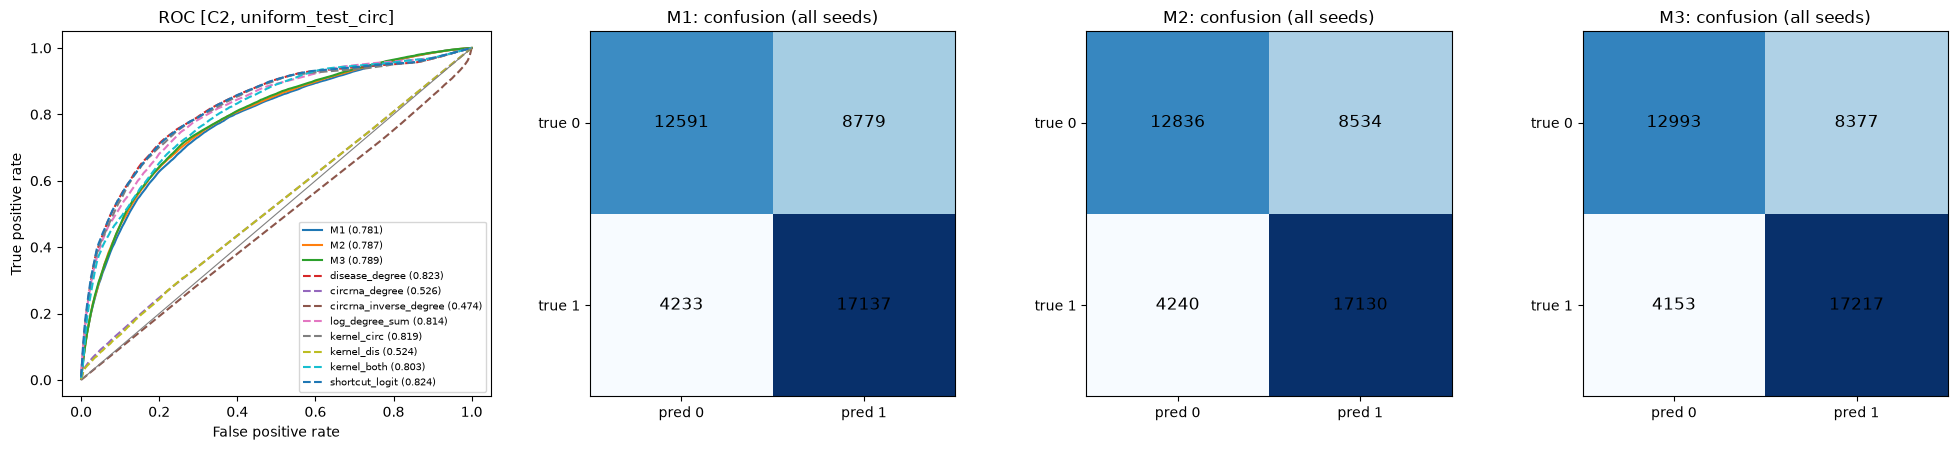


AUROC by circRNA status [C2, uniform_test_circ] (mean over seeds):
                          stratum   pos   neg    M1    M2    M3 disease_degree shortcut_logit
warm (circRNA has training pairs)  6800  5863 0.834 0.835 0.836          0.845          0.847
          cold (circRNA has none) 14570 15507 0.795 0.796 0.798          0.813          0.812


In [27]:
# 10_protocol_ladder - Cell 13: pair-level report for the run set in RUN: metrics, baselines from TRAINING pairs only, and AUROC split by whether the circRNA has training pairs
from sklearn.linear_model import LogisticRegression
from circmtl import ladder as L
RUN = "C2"                                                      # same value as in Cell 12
SCHEME = {"A": "degree_matched", "C": "uniform_pair", "C2": "uniform_test_circ"}[RUN]
nC, nD = gd.N["circRNA"], gd.N["disease"]
if "_bs_host" not in globals():
    _bs_host = baseline_scores                                # the host-gene version from Cell 1
PAIR = {"on": True, "tag": RUN}

def baseline_scores(d, kind):
    if not PAIR["on"]:
        return _bs_host(d, kind)
    out = np.zeros(len(d))
    for (s, k), ix in d.groupby(["seed", "fold"]).indices.items():
        fd = L.pair_level_fold(gd, int(s), int(k))
        Y = L.label_matrix(fd["disease_train"], nC, nD); dd, dc = Y.sum(0), Y.sum(1)
        c, t = d["c"].to_numpy()[ix], d["t"].to_numpy()[ix]
        if kind == "disease_degree":          sc = dd[t]
        elif kind == "circrna_degree":        sc = dc[c]
        elif kind == "circrna_inverse_degree": sc = -dc[c]
        elif kind == "log_degree_sum":        sc = np.log1p(dd[t]) + np.log1p(dc[c])
        elif kind.startswith("kernel_"):      sc = L.kernel_scores(Y)[kind][c, t]
        elif kind == "shortcut_logit":
            z = np.load(OUT / "frozen_pair" / f"neg{PAIR['tag']}_seed{int(s)}_fold{int(k)}.npz")
            pv = np.vstack([fd["disease_val"], z["neg_val"]]); yv_ = np.r_[np.ones(len(fd["disease_val"])), np.zeros(len(z["neg_val"]))]
            clf = LogisticRegression(C=1.0).fit(np.c_[np.log1p(dd[pv[:, 1]]), np.log1p(dc[pv[:, 0]])], yv_)    # fitted on validation only
            sc = clf.decision_function(np.c_[np.log1p(dd[t]), np.log1p(dc[c])])
        else:
            raise ValueError(kind)
        out[ix] = sc
    return out

P_R = pd.concat([pd.read_csv(f) for m in ("M1", "M2", "M3") for f in sorted((OUT / f"pred_{RUN}").glob(f"pred_{m}_seed*_fold*.csv"))], ignore_index=True)
print(f"run {RUN}: {P_R.groupby('model')[['seed', 'fold']].apply(lambda g: len(g.drop_duplicates()))[['M1', 'M2', 'M3']].to_dict()} seed-folds per model (expect 50 each)")
BL = ("disease_degree", "circrna_degree", "circrna_inverse_degree", "log_degree_sum", "kernel_circ", "kernel_dis", "kernel_both", "shortcut_logit")
R_tab, R_seed = report(P_R, ["M1", "M2", "M3"], tag=RUN, scheme=SCHEME, baselines=BL)

# AUROC split by whether the pair's circRNA has >= 1 training pair (removes the held-out artifact inside each stratum)
warm = np.zeros(len(P_R), bool)
for (s, k), ix in P_R.groupby(["seed", "fold"]).indices.items():
    dc = np.bincount(L.pair_level_fold(gd, int(s), int(k))["disease_train"][:, 0], minlength=nC)
    warm[ix] = dc[P_R["c"].to_numpy()[ix]] > 0
base = P_R[P_R["model"] == "M1"][["seed", "fold", "c", "t", "y"]].reset_index(drop=True)
warm_b = warm[(P_R["model"] == "M1").to_numpy()]
comp = {"disease_degree": baseline_scores(base, "disease_degree"), "shortcut_logit": baseline_scores(base, "shortcut_logit")}
rows = []
for name, msk in (("warm (circRNA has training pairs)", True), ("cold (circRNA has none)", False)):
    r = {"stratum": name}
    sel_b = warm_b == msk
    r["pos"], r["neg"] = int(base["y"][sel_b].sum()), int((1 - base["y"][sel_b]).sum())
    for m in ("M1", "M2", "M3"):
        g = P_R[(P_R["model"] == m).to_numpy() & (warm == msk)]
        a = [roc_auc_score(x["y"], x["score_rank"]) for _, x in g.groupby("seed") if 0 < x["y"].sum() < len(x)]
        r[m] = f"{np.mean(a):.3f}" if a else "n/a"
    for cname, v in comp.items():
        a = [roc_auc_score(base["y"][sel_b & (base["seed"] == s).to_numpy()], v[sel_b & (base["seed"] == s).to_numpy()]) for s in range(10)
             if 0 < base["y"][sel_b & (base["seed"] == s).to_numpy()].sum() < (sel_b & (base["seed"] == s).to_numpy()).sum()]
        r[cname] = f"{np.mean(a):.3f}" if a else "n/a"
    rows.append(r)
print(f"\nAUROC by circRNA status [{RUN}, {SCHEME}] (mean over seeds):")
print(pd.DataFrame(rows).to_string(index=False))
PAIR["on"] = False                                           # restore the host-gene baselines for earlier cells

## Cell 20: paired bootstrap C2

In [ ]:
# 10_protocol_ladder - Cell 14: paired bootstrap over host groups for one pair-level run (run Cell 13 first, with the same RUN)
N_BOOT = 1000
RUN = "C2"
PAIR["on"], PAIR["tag"] = True, RUN
W = P_R.pivot_table(index=["seed", "fold", "c", "t", "y"], columns="model", values="score_rank").reset_index()
assert W[["M1", "M2", "M3"]].notna().all().all(), "models are not aligned on the same test pairs"
for b in ("disease_degree", "shortcut_logit"):
    v = baseline_scores(W, b)                                               # from TRAINING pairs only
    W[b] = pd.Series(v).groupby([W["seed"], W["fold"]]).rank(pct=True).to_numpy()
PAIR["on"] = False
cols = ["M1", "M2", "M3", "disease_degree", "shortcut_logit"]
yv, sd = W["y"].to_numpy(), W["seed"].to_numpy()
V = {c: W[c].to_numpy() for c in cols}
seed_ix = [np.flatnonzero(sd == s) for s in sorted(W["seed"].unique())]
ug, gi = np.unique(gd.groups[W["c"].to_numpy()], return_inverse=True)
auc = lambda c, w=None: float(np.mean([roc_auc_score(yv[ix], V[c][ix], sample_weight=None if w is None else w[ix]) for ix in seed_ix]))
point = {c: auc(c) for c in cols}
rb, boots = np.random.default_rng(0), {c: [] for c in cols}
for _ in range(N_BOOT):
    w = np.bincount(rb.integers(0, len(ug), len(ug)), minlength=len(ug))[gi].astype(float)
    for c in cols:
        boots[c].append(auc(c, w))
boots = {c: np.array(v) for c, v in boots.items()}
print(f"run {RUN}: paired bootstrap over host groups ({N_BOOT} resamples), AUROC difference [95% CI]:")
for a, b in (("M3", "M1"), ("M2", "M1"), ("M3", "M2"), ("M1", "disease_degree"), ("M2", "disease_degree"), ("M3", "disease_degree"),
             ("M1", "shortcut_logit"), ("M2", "shortcut_logit"), ("M3", "shortcut_logit")):
    d = boots[a] - boots[b]
    print(f"   {a} - {b:15s} {point[a] - point[b]:+.4f} [{np.percentile(d, 2.5):+.4f}, {np.percentile(d, 97.5):+.4f}]")

run C2: paired bootstrap over host groups (1000 resamples), AUROC difference [95% CI]:
   M3 - M1              +0.0082 [+0.0058, +0.0106]
   M2 - M1              +0.0055 [+0.0032, +0.0078]
   M3 - M2              +0.0027 [+0.0008, +0.0045]
   M1 - disease_degree  -0.0423 [-0.0479, -0.0361]
   M2 - disease_degree  -0.0368 [-0.0422, -0.0304]
   M3 - disease_degree  -0.0341 [-0.0398, -0.0277]
   M1 - shortcut_logit  -0.0426 [-0.0478, -0.0372]
   M2 - shortcut_logit  -0.0371 [-0.0419, -0.0314]
   M3 - shortcut_logit  -0.0344 [-0.0395, -0.0288]


## Cell 21: the leak audit

In [35]:

# 10_protocol_ladder - Cell 15: LEAK AUDIT (a control, never a result) - the same kernel-propagation baselines with kernels built from ALL labels, on the frozen pair-level test pairs (no neural model)
from circmtl import ladder as L
nC, nD = gd.N["circRNA"], gd.N["disease"]
Yfull = L.label_matrix(gd.E["disease"], nC, nD)                                   # every known pair, including test and validation pairs
KS_leak = L.kernel_scores(Yfull)                                                  # one matrix serves every fold: it is fold-independent
store = {}
for s in range(10):
    for k in range(5):
        fd = L.pair_level_fold(gd, s, k)
        KS_mask = L.kernel_scores(L.label_matrix(fd["disease_train"], nC, nD))    # the same baselines from training pairs only
        pos = fd["disease_test"]
        for tag in ("A", "C", "C2"):
            z = np.load(OUT / "frozen_pair" / f"neg{tag}_seed{s}_fold{k}.npz")
            pr = np.vstack([pos, z["neg_test"]]); y = np.r_[np.ones(len(pos)), np.zeros(len(z["neg_test"]))]
            for name in ("kernel_circ", "kernel_dis", "kernel_both"):
                for kind, KS in (("masked", KS_mask), ("LEAKY", KS_leak)):
                    d = store.setdefault((tag, name, kind, s), {"y": [], "sc": []})
                    d["y"].append(y); d["sc"].append(pd.Series(KS[name][pr[:, 0], pr[:, 1]]).rank(pct=True).to_numpy())
rows = []
for name in ("kernel_circ", "kernel_dis", "kernel_both"):
    r = {"baseline": name}
    for tag in ("A", "C", "C2"):
        for kind in ("masked", "LEAKY"):
            a = [roc_auc_score(np.concatenate(store[(tag, name, kind, s)]["y"]), np.concatenate(store[(tag, name, kind, s)]["sc"])) for s in range(10)]
            r[f"{tag} {kind}"] = f"{np.mean(a):.3f}"
    rows.append(r)
print("kernel propagation, AUROC on the frozen pair-level test pairs (mean over 10 seeds): kernels from training pairs only (masked) vs from ALL labels (LEAKY)")
print(pd.DataFrame(rows).to_string(index=False))

kernel propagation, AUROC on the frozen pair-level test pairs (mean over 10 seeds): kernels from training pairs only (masked) vs from ALL labels (LEAKY)
   baseline A masked A LEAKY C masked C LEAKY C2 masked C2 LEAKY
kernel_circ    0.504   0.788    0.822   0.929     0.819    0.930
 kernel_dis    0.500   0.223    0.329   0.250     0.524    0.238
kernel_both    0.500   0.774    0.755   0.928     0.803    0.925


## Cell 22: the control run  A

In [37]:
# 10_protocol_ladder - Cell 22: SHUFFLED-AUXILIARY CONTROL - M3 trained with the miRNA/RBP edges reassigned among circRNAs (a control; resumable; locked when finished)
import copy, importlib
from circmtl import ladder as L
importlib.reload(L)
RUN = "A"                                                    # "A" first; "C2" only if time allows
SCHEME = {"A": "degree_matched", "C": "uniform_pair", "C2": "uniform_test_circ"}[RUN]
OUTR = OUT / f"pred_{RUN}_M3shuf"; OUTR.mkdir(exist_ok=True)
assert not (OUTR / "DONE.txt").exists(), "this control is finished and locked; a rerun is only allowed to fix a failed assertion (log it in run_log)"
nC, nD = gd.N["circRNA"], gd.N["disease"]
gd_real = gd

def shuffled_gd(seed):
    """A copy of the graph whose miRNA/RBP edges (and their known-edge codes) have their circRNA endpoints permuted."""
    pi = np.random.default_rng(90_000 + seed).permutation(nC)
    assert (pi == np.arange(nC)).mean() < 0.01, "permutation keeps too many circRNAs in place"
    g = copy.copy(gd_real)
    g.E = {r: (np.c_[pi[gd_real.E[r][:, 0]], gd_real.E[r][:, 1]] if r in AUX else gd_real.E[r]) for r in gd_real.E}
    g.known_codes = {r: (np.unique(L.codes(pi[v // gd_real.N[r]], v % gd_real.N[r], gd_real.N[r])) if r in AUX else v) for r, v in gd_real.known_codes.items()}
    for r in AUX:                                              # same edge count and same degree multiset as the real edges
        assert len(g.E[r]) == len(gd_real.E[r]) and np.array_equal(np.sort(np.bincount(g.E[r][:, 0], minlength=nC)), np.sort(np.bincount(gd_real.E[r][:, 0], minlength=nC)))
    return g

AUX_W, t0, log = [0.1, 0.5, 1.0], time.time(), []
try:
    for s in range(10):
        gd_s = shuffled_gd(s)
        for k in range(5):
            fn = OUTR / f"pred_M3shuf_seed{s}_fold{k}.csv"
            if fn.exists():
                continue                                                         # resume
            gd = gd_s                                                            # train_one_l and predict_l read the global gd
            fd = L.pair_level_fold(gd_s, s, k)                                   # same disease folds as A / C2; shuffled auxiliary edges
            z = np.load(OUT / "frozen_pair" / f"neg{RUN}_seed{s}_fold{k}.npz"); neg_val, neg_test = z["neg_val"], z["neg_test"]
            L.check_fold_pair(gd_s, fd, neg_val, neg_test, SCHEME)
            tcodes = L.codes(fd["disease_train"][:, 0], fd["disease_train"][:, 1], nD)

            def neg_fn(sup, rng, fd=fd, tcodes=tcodes):
                if RUN == "A":
                    neg = L.degree_train_negatives(nD, sup, fd["disease_train"], tcodes, rng, k=TRAIN["neg_k"])
                else:
                    neg = L.uniform_train_negatives(nD, sup, fd["train"], tcodes, rng, k=TRAIN["neg_k"])
                L.check_train_negatives(nD, neg, fd)
                return neg

            cands = []
            for w in AUX_W:
                model, x, hist, best, vs = train_one_l(fd, "M3", aux_w=w, seed=s, disease_neg_fn=neg_fn, val_neg=neg_val)
                cands.append((best["auc"], w, model, x, best["epoch"], vs))
            val_auc, w, model, x, ep, (vsp, vsn) = max(cands, key=lambda c: c[0])
            thr, vf1 = L.best_f1_threshold(np.r_[np.ones(len(vsp)), np.zeros(len(vsn))], np.r_[vsp, vsn])
            predict_l(model, x, fd, "M3", neg_test, scheme=SCHEME).assign(model="M3_shuf", seed=s, fold=k, aux_w=w, best_epoch=ep, val_auc=val_auc,
                                                                         threshold=thr, val_f1=vf1).to_csv(fn, index=False)
            log.append({"seed": s, "fold": k, "aux_w": w, "best_epoch": ep, "val_auc": round(val_auc, 3)})
            print(f"  {RUN} M3_shuf seed {s} fold {k} | w {w} | best epoch {ep:3d} | val {val_auc:.3f} | {time.time() - t0:6.0f}s")
finally:
    gd = gd_real                                                                 # always restore the real graph
if log:
    pd.DataFrame(log).to_csv(OUTR / "run_log.csv", mode="a", index=False, header=not (OUTR / "run_log.csv").exists())
n_files = len(list(OUTR.glob("pred_M3shuf_seed*_fold*.csv")))
if n_files == 50:
    (OUTR / "DONE.txt").write_text(f"{RUN} M3_shuf complete: 50 prediction files, written {time.strftime('%Y-%m-%d %H:%M')}\n")
print(f"run {RUN} M3_shuf: {n_files} of 50 prediction files | {time.time() - t0:.0f}s this session")

  A M3_shuf seed 0 fold 0 | w 0.1 | best epoch  63 | val 0.562 |     24s
  A M3_shuf seed 0 fold 1 | w 0.5 | best epoch  78 | val 0.571 |     57s
  A M3_shuf seed 0 fold 2 | w 1.0 | best epoch  51 | val 0.566 |     79s
  A M3_shuf seed 0 fold 3 | w 0.1 | best epoch  74 | val 0.583 |    107s
  A M3_shuf seed 0 fold 4 | w 0.5 | best epoch 115 | val 0.594 |    145s
  A M3_shuf seed 1 fold 0 | w 0.1 | best epoch  62 | val 0.554 |    174s
  A M3_shuf seed 1 fold 1 | w 1.0 | best epoch  50 | val 0.544 |    194s
  A M3_shuf seed 1 fold 2 | w 0.5 | best epoch  73 | val 0.558 |    221s
  A M3_shuf seed 1 fold 3 | w 0.1 | best epoch 175 | val 0.575 |    253s
  A M3_shuf seed 1 fold 4 | w 0.5 | best epoch 132 | val 0.537 |    295s
  A M3_shuf seed 2 fold 0 | w 0.1 | best epoch  93 | val 0.586 |    324s
  A M3_shuf seed 2 fold 1 | w 0.5 | best epoch  62 | val 0.596 |    362s
  A M3_shuf seed 2 fold 2 | w 0.5 | best epoch 140 | val 0.562 |    399s
  A M3_shuf seed 2 fold 3 | w 0.5 | best epoch  80 

## Cell 23: the comparison A

In [38]:
# 10_protocol_ladder - Cell 23: shuffled-auxiliary control - compare M3 with M3_shuf (same test pairs, paired bootstrap over host groups)
RUN = "A"                                                    # same as in Cell 16
SCHEME = {"A": "degree_matched", "C": "uniform_pair", "C2": "uniform_test_circ"}[RUN]
rd = lambda m, folder, pat: [pd.read_csv(f) for f in sorted((OUT / folder).glob(f"pred_{pat}_seed*_fold*.csv"))]
P_all = pd.concat(rd("M1", f"pred_{RUN}", "M1") + rd("M2", f"pred_{RUN}", "M2") + rd("M3", f"pred_{RUN}", "M3") + rd("M3_shuf", f"pred_{RUN}_M3shuf", "M3shuf"), ignore_index=True)
assert set(P_all["scheme"]) == {SCHEME}, f"predictions hold {sorted(set(P_all['scheme']))}, expected {SCHEME}"
print("seed-folds per model:", P_all.groupby("model")[["seed", "fold"]].apply(lambda g: len(g.drop_duplicates())).to_dict())
W = P_all.pivot_table(index=["seed", "fold", "c", "t", "y"], columns="model", values="score_rank").reset_index()
cols = ["M1", "M2", "M3", "M3_shuf"]
assert W[cols].notna().all().all(), "models are not aligned on the same test pairs"
yv, sd = W["y"].to_numpy(), W["seed"].to_numpy()
V = {c: W[c].to_numpy() for c in cols}
seed_ix = [np.flatnonzero(sd == s) for s in sorted(W["seed"].unique())]
ug, gi = np.unique(gd.groups[W["c"].to_numpy()], return_inverse=True)
auc = lambda c, w=None: float(np.mean([roc_auc_score(yv[ix], V[c][ix], sample_weight=None if w is None else w[ix]) for ix in seed_ix]))
point = {c: auc(c) for c in cols}
rb, boots = np.random.default_rng(0), {c: [] for c in cols}
for _ in range(1000):
    w = np.bincount(rb.integers(0, len(ug), len(ug)), minlength=len(ug))[gi].astype(float)
    for c in cols:
        boots[c].append(auc(c, w))
boots = {c: np.array(v) for c, v in boots.items()}
print(f"run {RUN}: AUROC  M1 {point['M1']:.4f} | M2 {point['M2']:.4f} | M3 {point['M3']:.4f} | M3_shuf {point['M3_shuf']:.4f}\n")
for a, b in (("M3", "M3_shuf"), ("M3_shuf", "M1"), ("M3", "M1")):
    d = boots[a] - boots[b]
    print(f"   {a} - {b:8s} {point[a] - point[b]:+.4f} [{np.percentile(d, 2.5):+.4f}, {np.percentile(d, 97.5):+.4f}]")
d = boots["M3"] - boots["M3_shuf"]
gain = point["M3"] - point["M1"]
print(f"\nshare of the M3 - M1 gain that disappears when the edges are shuffled: {(point['M3'] - point['M3_shuf']) / gain:.0%}" if abs(gain) > 0.002 else "\n(M3 - M1 is below 0.002 here, so a share of the gain is not meaningful)")
dh = boots["M3_shuf"] - boots["M1"]
print("RULE (registered):", "CONTENT USED" if (np.percentile(d, 2.5) > 0 and point["M3"] > point["M3_shuf"] and np.percentile(dh, 97.5) > 0) else "CONTENT USE NOT DEMONSTRATED")

seed-folds per model: {'M1': 50, 'M2': 50, 'M3': 50, 'M3_shuf': 50}
run A: AUROC  M1 0.5385 | M2 0.5425 | M3 0.5460 | M3_shuf 0.5435

   M3 - M3_shuf  +0.0025 [-0.0025, +0.0078]
   M3_shuf - M1       +0.0049 [-0.0005, +0.0103]
   M3 - M1       +0.0075 [+0.0019, +0.0132]

share of the M3 - M1 gain that disappears when the edges are shuffled: 34%
RULE (registered): CONTENT USE NOT DEMONSTRATED


## Cell 22: the control run  C

In [39]:
# 10_protocol_ladder - Cell 22: SHUFFLED-AUXILIARY CONTROL - M3 trained with the miRNA/RBP edges reassigned among circRNAs (a control; resumable; locked when finished)
import copy, importlib
from circmtl import ladder as L
importlib.reload(L)
RUN = "C"                                                    # "A" first; "C2" only if time allows
SCHEME = {"A": "degree_matched", "C": "uniform_pair", "C2": "uniform_test_circ"}[RUN]
OUTR = OUT / f"pred_{RUN}_M3shuf"; OUTR.mkdir(exist_ok=True)
assert not (OUTR / "DONE.txt").exists(), "this control is finished and locked; a rerun is only allowed to fix a failed assertion (log it in run_log)"
nC, nD = gd.N["circRNA"], gd.N["disease"]
gd_real = gd

def shuffled_gd(seed):
    """A copy of the graph whose miRNA/RBP edges (and their known-edge codes) have their circRNA endpoints permuted."""
    pi = np.random.default_rng(90_000 + seed).permutation(nC)
    assert (pi == np.arange(nC)).mean() < 0.01, "permutation keeps too many circRNAs in place"
    g = copy.copy(gd_real)
    g.E = {r: (np.c_[pi[gd_real.E[r][:, 0]], gd_real.E[r][:, 1]] if r in AUX else gd_real.E[r]) for r in gd_real.E}
    g.known_codes = {r: (np.unique(L.codes(pi[v // gd_real.N[r]], v % gd_real.N[r], gd_real.N[r])) if r in AUX else v) for r, v in gd_real.known_codes.items()}
    for r in AUX:                                              # same edge count and same degree multiset as the real edges
        assert len(g.E[r]) == len(gd_real.E[r]) and np.array_equal(np.sort(np.bincount(g.E[r][:, 0], minlength=nC)), np.sort(np.bincount(gd_real.E[r][:, 0], minlength=nC)))
    return g

AUX_W, t0, log = [0.1, 0.5, 1.0], time.time(), []
try:
    for s in range(10):
        gd_s = shuffled_gd(s)
        for k in range(5):
            fn = OUTR / f"pred_M3shuf_seed{s}_fold{k}.csv"
            if fn.exists():
                continue                                                         # resume
            gd = gd_s                                                            # train_one_l and predict_l read the global gd
            fd = L.pair_level_fold(gd_s, s, k)                                   # same disease folds as A / C2; shuffled auxiliary edges
            z = np.load(OUT / "frozen_pair" / f"neg{RUN}_seed{s}_fold{k}.npz"); neg_val, neg_test = z["neg_val"], z["neg_test"]
            L.check_fold_pair(gd_s, fd, neg_val, neg_test, SCHEME)
            tcodes = L.codes(fd["disease_train"][:, 0], fd["disease_train"][:, 1], nD)

            def neg_fn(sup, rng, fd=fd, tcodes=tcodes):
                if RUN == "A":
                    neg = L.degree_train_negatives(nD, sup, fd["disease_train"], tcodes, rng, k=TRAIN["neg_k"])
                else:
                    neg = L.uniform_train_negatives(nD, sup, fd["train"], tcodes, rng, k=TRAIN["neg_k"])
                L.check_train_negatives(nD, neg, fd)
                return neg

            cands = []
            for w in AUX_W:
                model, x, hist, best, vs = train_one_l(fd, "M3", aux_w=w, seed=s, disease_neg_fn=neg_fn, val_neg=neg_val)
                cands.append((best["auc"], w, model, x, best["epoch"], vs))
            val_auc, w, model, x, ep, (vsp, vsn) = max(cands, key=lambda c: c[0])
            thr, vf1 = L.best_f1_threshold(np.r_[np.ones(len(vsp)), np.zeros(len(vsn))], np.r_[vsp, vsn])
            predict_l(model, x, fd, "M3", neg_test, scheme=SCHEME).assign(model="M3_shuf", seed=s, fold=k, aux_w=w, best_epoch=ep, val_auc=val_auc,
                                                                         threshold=thr, val_f1=vf1).to_csv(fn, index=False)
            log.append({"seed": s, "fold": k, "aux_w": w, "best_epoch": ep, "val_auc": round(val_auc, 3)})
            print(f"  {RUN} M3_shuf seed {s} fold {k} | w {w} | best epoch {ep:3d} | val {val_auc:.3f} | {time.time() - t0:6.0f}s")
finally:
    gd = gd_real                                                                 # always restore the real graph
if log:
    pd.DataFrame(log).to_csv(OUTR / "run_log.csv", mode="a", index=False, header=not (OUTR / "run_log.csv").exists())
n_files = len(list(OUTR.glob("pred_M3shuf_seed*_fold*.csv")))
if n_files == 50:
    (OUTR / "DONE.txt").write_text(f"{RUN} M3_shuf complete: 50 prediction files, written {time.strftime('%Y-%m-%d %H:%M')}\n")
print(f"run {RUN} M3_shuf: {n_files} of 50 prediction files | {time.time() - t0:.0f}s this session")

  C M3_shuf seed 0 fold 0 | w 0.1 | best epoch 122 | val 0.864 |     43s
  C M3_shuf seed 0 fold 1 | w 1.0 | best epoch 159 | val 0.848 |     95s
  C M3_shuf seed 0 fold 2 | w 0.5 | best epoch  82 | val 0.856 |    127s
  C M3_shuf seed 0 fold 3 | w 0.1 | best epoch  69 | val 0.870 |    162s
  C M3_shuf seed 0 fold 4 | w 0.1 | best epoch  88 | val 0.874 |    195s
  C M3_shuf seed 1 fold 0 | w 0.1 | best epoch 165 | val 0.859 |    239s
  C M3_shuf seed 1 fold 1 | w 1.0 | best epoch 121 | val 0.861 |    284s
  C M3_shuf seed 1 fold 2 | w 0.5 | best epoch 126 | val 0.859 |    330s
  C M3_shuf seed 1 fold 3 | w 1.0 | best epoch 157 | val 0.842 |    379s
  C M3_shuf seed 1 fold 4 | w 0.1 | best epoch 107 | val 0.863 |    418s
  C M3_shuf seed 2 fold 0 | w 0.1 | best epoch 115 | val 0.864 |    456s
  C M3_shuf seed 2 fold 1 | w 0.1 | best epoch  85 | val 0.886 |    487s
  C M3_shuf seed 2 fold 2 | w 1.0 | best epoch  94 | val 0.842 |    523s
  C M3_shuf seed 2 fold 3 | w 0.1 | best epoch 108 

## Cell 23: the comparison C

In [40]:
# 10_protocol_ladder - Cell 23: shuffled-auxiliary control - compare M3 with M3_shuf (same test pairs, paired bootstrap over host groups)
RUN = "C"                                                    # same as in Cell 16
SCHEME = {"A": "degree_matched", "C": "uniform_pair", "C2": "uniform_test_circ"}[RUN]
rd = lambda m, folder, pat: [pd.read_csv(f) for f in sorted((OUT / folder).glob(f"pred_{pat}_seed*_fold*.csv"))]
P_all = pd.concat(rd("M1", f"pred_{RUN}", "M1") + rd("M2", f"pred_{RUN}", "M2") + rd("M3", f"pred_{RUN}", "M3") + rd("M3_shuf", f"pred_{RUN}_M3shuf", "M3shuf"), ignore_index=True)
assert set(P_all["scheme"]) == {SCHEME}, f"predictions hold {sorted(set(P_all['scheme']))}, expected {SCHEME}"
print("seed-folds per model:", P_all.groupby("model")[["seed", "fold"]].apply(lambda g: len(g.drop_duplicates())).to_dict())
W = P_all.pivot_table(index=["seed", "fold", "c", "t", "y"], columns="model", values="score_rank").reset_index()
cols = ["M1", "M2", "M3", "M3_shuf"]
assert W[cols].notna().all().all(), "models are not aligned on the same test pairs"
yv, sd = W["y"].to_numpy(), W["seed"].to_numpy()
V = {c: W[c].to_numpy() for c in cols}
seed_ix = [np.flatnonzero(sd == s) for s in sorted(W["seed"].unique())]
ug, gi = np.unique(gd.groups[W["c"].to_numpy()], return_inverse=True)
auc = lambda c, w=None: float(np.mean([roc_auc_score(yv[ix], V[c][ix], sample_weight=None if w is None else w[ix]) for ix in seed_ix]))
point = {c: auc(c) for c in cols}
rb, boots = np.random.default_rng(0), {c: [] for c in cols}
for _ in range(1000):
    w = np.bincount(rb.integers(0, len(ug), len(ug)), minlength=len(ug))[gi].astype(float)
    for c in cols:
        boots[c].append(auc(c, w))
boots = {c: np.array(v) for c, v in boots.items()}
print(f"run {RUN}: AUROC  M1 {point['M1']:.4f} | M2 {point['M2']:.4f} | M3 {point['M3']:.4f} | M3_shuf {point['M3_shuf']:.4f}\n")
for a, b in (("M3", "M3_shuf"), ("M3_shuf", "M1"), ("M3", "M1")):
    d = boots[a] - boots[b]
    print(f"   {a} - {b:8s} {point[a] - point[b]:+.4f} [{np.percentile(d, 2.5):+.4f}, {np.percentile(d, 97.5):+.4f}]")
d = boots["M3"] - boots["M3_shuf"]
gain = point["M3"] - point["M1"]
print(f"\nshare of the M3 - M1 gain that disappears when the edges are shuffled: {(point['M3'] - point['M3_shuf']) / gain:.0%}" if abs(gain) > 0.002 else "\n(M3 - M1 is below 0.002 here, so a share of the gain is not meaningful)")
dh = boots["M3_shuf"] - boots["M1"]
print("RULE (registered):", "CONTENT USED" if (np.percentile(d, 2.5) > 0 and point["M3"] > point["M3_shuf"] and np.percentile(dh, 97.5) > 0) else "CONTENT USE NOT DEMONSTRATED")

seed-folds per model: {'M1': 50, 'M2': 50, 'M3': 50, 'M3_shuf': 50}
run C: AUROC  M1 0.8638 | M2 0.8634 | M3 0.8640 | M3_shuf 0.8631

   M3 - M3_shuf  +0.0009 [-0.0009, +0.0026]
   M3_shuf - M1       -0.0007 [-0.0024, +0.0010]
   M3 - M1       +0.0002 [-0.0017, +0.0020]

(M3 - M1 is below 0.002 here, so a share of the gain is not meaningful)
RULE (registered): CONTENT USE NOT DEMONSTRATED


## Cell 22: the control run  C2

In [41]:
# 10_protocol_ladder - Cell 22: SHUFFLED-AUXILIARY CONTROL - M3 trained with the miRNA/RBP edges reassigned among circRNAs (a control; resumable; locked when finished)
import copy, importlib
from circmtl import ladder as L
importlib.reload(L)
RUN = "C2"                                                    # "A" first; "C2" only if time allows
SCHEME = {"A": "degree_matched", "C": "uniform_pair", "C2": "uniform_test_circ"}[RUN]
OUTR = OUT / f"pred_{RUN}_M3shuf"; OUTR.mkdir(exist_ok=True)
assert not (OUTR / "DONE.txt").exists(), "this control is finished and locked; a rerun is only allowed to fix a failed assertion (log it in run_log)"
nC, nD = gd.N["circRNA"], gd.N["disease"]
gd_real = gd

def shuffled_gd(seed):
    """A copy of the graph whose miRNA/RBP edges (and their known-edge codes) have their circRNA endpoints permuted."""
    pi = np.random.default_rng(90_000 + seed).permutation(nC)
    assert (pi == np.arange(nC)).mean() < 0.01, "permutation keeps too many circRNAs in place"
    g = copy.copy(gd_real)
    g.E = {r: (np.c_[pi[gd_real.E[r][:, 0]], gd_real.E[r][:, 1]] if r in AUX else gd_real.E[r]) for r in gd_real.E}
    g.known_codes = {r: (np.unique(L.codes(pi[v // gd_real.N[r]], v % gd_real.N[r], gd_real.N[r])) if r in AUX else v) for r, v in gd_real.known_codes.items()}
    for r in AUX:                                              # same edge count and same degree multiset as the real edges
        assert len(g.E[r]) == len(gd_real.E[r]) and np.array_equal(np.sort(np.bincount(g.E[r][:, 0], minlength=nC)), np.sort(np.bincount(gd_real.E[r][:, 0], minlength=nC)))
    return g

AUX_W, t0, log = [0.1, 0.5, 1.0], time.time(), []
try:
    for s in range(10):
        gd_s = shuffled_gd(s)
        for k in range(5):
            fn = OUTR / f"pred_M3shuf_seed{s}_fold{k}.csv"
            if fn.exists():
                continue                                                         # resume
            gd = gd_s                                                            # train_one_l and predict_l read the global gd
            fd = L.pair_level_fold(gd_s, s, k)                                   # same disease folds as A / C2; shuffled auxiliary edges
            z = np.load(OUT / "frozen_pair" / f"neg{RUN}_seed{s}_fold{k}.npz"); neg_val, neg_test = z["neg_val"], z["neg_test"]
            L.check_fold_pair(gd_s, fd, neg_val, neg_test, SCHEME)
            tcodes = L.codes(fd["disease_train"][:, 0], fd["disease_train"][:, 1], nD)

            def neg_fn(sup, rng, fd=fd, tcodes=tcodes):
                if RUN == "A":
                    neg = L.degree_train_negatives(nD, sup, fd["disease_train"], tcodes, rng, k=TRAIN["neg_k"])
                else:
                    neg = L.uniform_train_negatives(nD, sup, fd["train"], tcodes, rng, k=TRAIN["neg_k"])
                L.check_train_negatives(nD, neg, fd)
                return neg

            cands = []
            for w in AUX_W:
                model, x, hist, best, vs = train_one_l(fd, "M3", aux_w=w, seed=s, disease_neg_fn=neg_fn, val_neg=neg_val)
                cands.append((best["auc"], w, model, x, best["epoch"], vs))
            val_auc, w, model, x, ep, (vsp, vsn) = max(cands, key=lambda c: c[0])
            thr, vf1 = L.best_f1_threshold(np.r_[np.ones(len(vsp)), np.zeros(len(vsn))], np.r_[vsp, vsn])
            predict_l(model, x, fd, "M3", neg_test, scheme=SCHEME).assign(model="M3_shuf", seed=s, fold=k, aux_w=w, best_epoch=ep, val_auc=val_auc,
                                                                         threshold=thr, val_f1=vf1).to_csv(fn, index=False)
            log.append({"seed": s, "fold": k, "aux_w": w, "best_epoch": ep, "val_auc": round(val_auc, 3)})
            print(f"  {RUN} M3_shuf seed {s} fold {k} | w {w} | best epoch {ep:3d} | val {val_auc:.3f} | {time.time() - t0:6.0f}s")
finally:
    gd = gd_real                                                                 # always restore the real graph
if log:
    pd.DataFrame(log).to_csv(OUTR / "run_log.csv", mode="a", index=False, header=not (OUTR / "run_log.csv").exists())
n_files = len(list(OUTR.glob("pred_M3shuf_seed*_fold*.csv")))
if n_files == 50:
    (OUTR / "DONE.txt").write_text(f"{RUN} M3_shuf complete: 50 prediction files, written {time.strftime('%Y-%m-%d %H:%M')}\n")
print(f"run {RUN} M3_shuf: {n_files} of 50 prediction files | {time.time() - t0:.0f}s this session")

  C2 M3_shuf seed 0 fold 0 | w 0.1 | best epoch 108 | val 0.788 |     38s
  C2 M3_shuf seed 0 fold 1 | w 0.5 | best epoch 251 | val 0.767 |     92s
  C2 M3_shuf seed 0 fold 2 | w 0.1 | best epoch  85 | val 0.783 |    127s
  C2 M3_shuf seed 0 fold 3 | w 0.1 | best epoch 151 | val 0.783 |    172s
  C2 M3_shuf seed 0 fold 4 | w 1.0 | best epoch 103 | val 0.800 |    210s
  C2 M3_shuf seed 1 fold 0 | w 0.5 | best epoch  75 | val 0.785 |    238s
  C2 M3_shuf seed 1 fold 1 | w 1.0 | best epoch 105 | val 0.798 |    276s
  C2 M3_shuf seed 1 fold 2 | w 1.0 | best epoch 131 | val 0.779 |    310s
  C2 M3_shuf seed 1 fold 3 | w 0.5 | best epoch 118 | val 0.765 |    357s
  C2 M3_shuf seed 1 fold 4 | w 0.1 | best epoch 107 | val 0.765 |    395s
  C2 M3_shuf seed 2 fold 0 | w 0.1 | best epoch 221 | val 0.773 |    448s
  C2 M3_shuf seed 2 fold 1 | w 0.5 | best epoch  86 | val 0.835 |    480s
  C2 M3_shuf seed 2 fold 2 | w 0.5 | best epoch  89 | val 0.804 |    513s
  C2 M3_shuf seed 2 fold 3 | w 0.1 | b

## Cell 23: the comparison C2

In [42]:
# 10_protocol_ladder - Cell 23: shuffled-auxiliary control - compare M3 with M3_shuf (same test pairs, paired bootstrap over host groups)
RUN = "C2"                                                    # same as in Cell 16
SCHEME = {"A": "degree_matched", "C": "uniform_pair", "C2": "uniform_test_circ"}[RUN]
rd = lambda m, folder, pat: [pd.read_csv(f) for f in sorted((OUT / folder).glob(f"pred_{pat}_seed*_fold*.csv"))]
P_all = pd.concat(rd("M1", f"pred_{RUN}", "M1") + rd("M2", f"pred_{RUN}", "M2") + rd("M3", f"pred_{RUN}", "M3") + rd("M3_shuf", f"pred_{RUN}_M3shuf", "M3shuf"), ignore_index=True)
assert set(P_all["scheme"]) == {SCHEME}, f"predictions hold {sorted(set(P_all['scheme']))}, expected {SCHEME}"
print("seed-folds per model:", P_all.groupby("model")[["seed", "fold"]].apply(lambda g: len(g.drop_duplicates())).to_dict())
W = P_all.pivot_table(index=["seed", "fold", "c", "t", "y"], columns="model", values="score_rank").reset_index()
cols = ["M1", "M2", "M3", "M3_shuf"]
assert W[cols].notna().all().all(), "models are not aligned on the same test pairs"
yv, sd = W["y"].to_numpy(), W["seed"].to_numpy()
V = {c: W[c].to_numpy() for c in cols}
seed_ix = [np.flatnonzero(sd == s) for s in sorted(W["seed"].unique())]
ug, gi = np.unique(gd.groups[W["c"].to_numpy()], return_inverse=True)
auc = lambda c, w=None: float(np.mean([roc_auc_score(yv[ix], V[c][ix], sample_weight=None if w is None else w[ix]) for ix in seed_ix]))
point = {c: auc(c) for c in cols}
rb, boots = np.random.default_rng(0), {c: [] for c in cols}
for _ in range(1000):
    w = np.bincount(rb.integers(0, len(ug), len(ug)), minlength=len(ug))[gi].astype(float)
    for c in cols:
        boots[c].append(auc(c, w))
boots = {c: np.array(v) for c, v in boots.items()}
print(f"run {RUN}: AUROC  M1 {point['M1']:.4f} | M2 {point['M2']:.4f} | M3 {point['M3']:.4f} | M3_shuf {point['M3_shuf']:.4f}\n")
for a, b in (("M3", "M3_shuf"), ("M3_shuf", "M1"), ("M3", "M1")):
    d = boots[a] - boots[b]
    print(f"   {a} - {b:8s} {point[a] - point[b]:+.4f} [{np.percentile(d, 2.5):+.4f}, {np.percentile(d, 97.5):+.4f}]")
d = boots["M3"] - boots["M3_shuf"]
gain = point["M3"] - point["M1"]
print(f"\nshare of the M3 - M1 gain that disappears when the edges are shuffled: {(point['M3'] - point['M3_shuf']) / gain:.0%}" if abs(gain) > 0.002 else "\n(M3 - M1 is below 0.002 here, so a share of the gain is not meaningful)")
dh = boots["M3_shuf"] - boots["M1"]
print("RULE (registered):", "CONTENT USED" if (np.percentile(d, 2.5) > 0 and point["M3"] > point["M3_shuf"] and np.percentile(dh, 97.5) > 0) else "CONTENT USE NOT DEMONSTRATED")

seed-folds per model: {'M1': 50, 'M2': 50, 'M3': 50, 'M3_shuf': 50}
run C2: AUROC  M1 0.7810 | M2 0.7865 | M3 0.7892 | M3_shuf 0.7861

   M3 - M3_shuf  +0.0031 [+0.0007, +0.0054]
   M3_shuf - M1       +0.0051 [+0.0031, +0.0072]
   M3 - M1       +0.0082 [+0.0058, +0.0106]

share of the M3 - M1 gain that disappears when the edges are shuffled: 37%
RULE (registered): CONTENT USED


## Cell 24: auxiliary-channel positive control

In [43]:
# 10_protocol_ladder - Cell 24: AUXILIARY-CHANNEL POSITIVE CONTROL (diagnostic only, never a result)
# Plant a disease label that is a function of the circRNA's miRNA/RBP partner set (independent of its sequence features).
# M1 cannot see partners, so it should stay near chance; M2/M3 can, so they should learn it if this graph and encoder can carry partner information.
from circmtl.graph import _codes
nC, nD = gd.N["circRNA"], gd.N["disease"]
rng_pc = np.random.default_rng(321)
B = np.zeros((nC, gd.N["mirna"] + gd.N["rbp"]))
for r, off in (("mirna", 0), ("rbp", gd.N["mirna"])):
    B[gd.E[r][:, 0], off + gd.E[r][:, 1]] = 1.0                               # partner-set indicator of every circRNA
has_aux = B.sum(1) > 0
Bn = B / np.maximum(np.sqrt(B.sum(1, keepdims=True)), 1.0)
R = rng_pc.normal(size=(B.shape[1], nD))
pop = np.bincount(gd.E["disease"][:, 1], minlength=nD) + 1.0
syn_d = np.argmax(Bn @ R + 0.5 * np.log(pop), axis=1)                         # one synthetic disease per circRNA, a function of its partners only
idx = np.flatnonzero(has_aux)
E_syn = np.c_[idx, syn_d[idx]].astype(np.int64)                               # circRNAs without partner edges get no synthetic label
print(f"circRNAs with a partner edge (given a synthetic label): {len(idx)} of {nC} ({len(idx) / nC:.1%}) | distinct synthetic diseases used: {len(np.unique(E_syn[:, 1]))}")

def synthetic_fold(fd):
    out = dict(fd)
    for part in ("train", "val", "test"):
        out[f"disease_{part}"] = E_syn[np.isin(E_syn[:, 0], fd[part])]
    cnt = np.bincount(out["disease_train"][:, 1], minlength=nD).astype(float)
    p_deg = cnt / cnt.sum()
    def neg(pos, seed):
        r = np.random.default_rng(seed); t = r.choice(nD, size=len(pos), p=p_deg)
        bad = t == pos[:, 1]
        while bad.any():
            t[bad] = r.choice(nD, size=int(bad.sum()), p=p_deg); bad = t == pos[:, 1]
        return np.c_[pos[:, 0], t].astype(np.int64)
    out["neg_val"] = neg(out["disease_val"], 1)
    out["neg_test_degree_matched"] = neg(out["disease_test"], 2)
    return out

def auc_syn(model, x, fd, m):
    with torch.no_grad():
        hA = model.encode(x, *gd.to_edge_tensors(gd.inference_graph(fd, "test", graph_of(m), with_test_aux=True), device))
        return score_pairs(model, hA, "disease", fd["disease_test"], fd["neg_test_degree_matched"])[0]

real_known = gd.known_codes["disease"]
gd.known_codes["disease"] = np.unique(_codes(E_syn[:, 0], E_syn[:, 1], nD))   # training negatives avoid the synthetic positives
res = {m: [] for m in ("M1", "M2", "M3")}
try:
    for k in range(5):
        fd_syn = synthetic_fold(gd.load_fold(0, k))
        for m in res:
            model, x, hist, best, _ = train_one_l(fd_syn, m, aux_w=0.5, seed=0, val_neg=fd_syn["neg_val"])
            res[m].append(auc_syn(model, x, fd_syn, m))
            print(f"  fold {k} {m}: best epoch {best['epoch']:3d} | val {best['auc']:.3f} | test (degree-matched) {res[m][-1]:.3f}")
finally:
    gd.known_codes["disease"] = real_known                                     # always restore the real labels
print("\nplanted partner signal, seed 0, 5 folds, test AUROC (degree-matched negatives):")
for m, v in res.items():
    print(f"  {m}: mean {np.mean(v):.3f}  (range {min(v):.3f}-{max(v):.3f})")

circRNAs with a partner edge (given a synthetic label): 1326 of 1582 (83.8%) | distinct synthetic diseases used: 92
  fold 0 M1: best epoch  26 | val 0.554 | test (degree-matched) 0.556
  fold 0 M2: best epoch 175 | val 0.655 | test (degree-matched) 0.618
  fold 0 M3: best epoch  20 | val 0.546 | test (degree-matched) 0.574
  fold 1 M1: best epoch  58 | val 0.602 | test (degree-matched) 0.609
  fold 1 M2: best epoch 232 | val 0.686 | test (degree-matched) 0.670
  fold 1 M3: best epoch  35 | val 0.619 | test (degree-matched) 0.592
  fold 2 M1: best epoch  25 | val 0.591 | test (degree-matched) 0.573
  fold 2 M2: best epoch  34 | val 0.632 | test (degree-matched) 0.621
  fold 2 M3: best epoch  33 | val 0.629 | test (degree-matched) 0.600
  fold 3 M1: best epoch  50 | val 0.553 | test (degree-matched) 0.559
  fold 3 M2: best epoch  39 | val 0.556 | test (degree-matched) 0.593
  fold 3 M3: best epoch 198 | val 0.626 | test (degree-matched) 0.630
  fold 4 M1: best epoch  25 | val 0.584 | te

## Cell 25: the ceiling

In [ ]:
# 10_protocol_ladder - Cell 25: CEILING for the planted partner task (diagnostic only; no neural network): how well can simple learners recover it from the partner sets?
# Run right after Cell 24 (it reuses B, E_syn, synthetic_fold from that cell). Same folds, same circRNAs, same degree-matched negatives as the neural models.
from sklearn.linear_model import LogisticRegression
Bn_ = B / np.maximum(np.sqrt((B ** 2).sum(1, keepdims=True)), 1e-9)               # unit-length partner vectors
rows = {"logistic regression on the partner sets": [], "shared-partner vote (cosine)": []}
for k in range(5):
    fd_syn = synthetic_fold(gd.load_fold(0, k))
    tr, te = fd_syn["disease_train"], fd_syn["disease_test"]
    pos, neg = te, fd_syn["neg_test_degree_matched"]
    pr = np.vstack([pos, neg]); y = np.r_[np.ones(len(pos)), np.zeros(len(neg))]
    # (a) multinomial logistic regression: partner indicator vector -> synthetic disease, trained on the TRAINING circRNAs only
    clf = LogisticRegression(max_iter=500, C=1.0).fit(B[tr[:, 0]], tr[:, 1])
    col = {c: i for i, c in enumerate(clf.classes_)}
    Dsc = clf.decision_function(B[pr[:, 0]])
    s_lr = np.array([Dsc[i, col[d]] if d in col else -1e9 for i, d in enumerate(pr[:, 1])])
    # (b) shared-partner vote: sum of cosine similarities to the training circRNAs that carry the disease
    S = Bn_[pr[:, 0]] @ Bn_[tr[:, 0]].T
    s_vote = np.array([S[i, tr[:, 1] == d].sum() for i, d in enumerate(pr[:, 1])])
    rows["logistic regression on the partner sets"].append(roc_auc_score(y, s_lr))
    rows["shared-partner vote (cosine)"].append(roc_auc_score(y, s_vote))
print("ceiling on the planted partner task, seed 0, 5 folds, test AUROC (degree-matched negatives):")
for name, v in rows.items():
    print(f"  {name:42s} mean {np.mean(v):.3f}  (range {min(v):.3f}-{max(v):.3f})")
print("\nfor comparison, from Cell 24: M1 0.565 | M2 0.604 | M3 0.588;  feature-planted control (Cell 19, M1, fold 0): 0.941")

ceiling on the planted partner task, seed 0, 5 folds, test AUROC (degree-matched negatives):
  logistic regression on the partner sets    mean 0.771  (range 0.738-0.793)
  shared-partner vote (cosine)               mean 0.583  (range 0.558-0.602)

for comparison, from Cell 24: M1 0.565 | M2 0.604 | M3 0.588;  feature-planted control (Cell 19, M1, fold 0): 0.941


## Cell 26: how much real information can a simple learner extract?

In [ ]:
# 10_protocol_ladder - Cell 26: SIMPLE-LEARNER REFERENCE ON THE REAL LABELS (diagnostic baseline, no neural network)
# Same strict host-gene folds, same test pairs and the same frozen degree-matched negatives as M1-M3. Seed 0, five folds.
# Softmax regression: input vector of a circRNA -> disease, trained on the TRAINING pairs only; C is chosen on the validation pairs.

import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)
import time
from sklearn.linear_model import LogisticRegression

nC, nD = gd.N["circRNA"], gd.N["disease"]
Bp = np.zeros((nC, gd.N["mirna"] + gd.N["rbp"]))
for r, off in (("mirna", 0), ("rbp", gd.N["mirna"])):
    Bp[gd.E[r][:, 0], off + gd.E[r][:, 1]] = 1.0                               # partner-set indicator of every circRNA (visible at test, as for the models)
CS, t0 = (0.1, 1.0), time.time()
res = {"partner sets": [], "RNA-FM features + length": [], "both": []}
for k in range(5):
    fd = gd.load_fold(0, k)
    Xf = gd.features(fd).astype(np.float64)                                    # standardised with the fold's TRAINING mean and sd
    sets = {"partner sets": Bp, "RNA-FM features + length": Xf, "both": np.hstack([Bp, Xf])}
    tr = fd["disease_train"]
    for name, X in sets.items():
        best = None
        for C in CS:
            clf = LogisticRegression(max_iter=1000, C=C).fit(X[tr[:, 0]], tr[:, 1])
            col = {c: i for i, c in enumerate(clf.classes_)}
            def auc(pos, neg):
                pr = np.vstack([pos, neg]); y = np.r_[np.ones(len(pos)), np.zeros(len(neg))]
                Dsc = clf.decision_function(X[pr[:, 0]])
                s = np.array([Dsc[i, col[d]] if d in col else -1e9 for i, d in enumerate(pr[:, 1])])
                return roc_auc_score(y, s)
            v = auc(fd["disease_val"], fd["neg_val"])                          # choose C on VALIDATION only
            if best is None or v > best[0]:
                best = (v, C, auc(fd["disease_test"], fd["neg_test_degree_matched"]))
        res[name].append(best[2])
    print(f"  fold {k} done | {time.time() - t0:.0f}s")
print("\nsoftmax regression on the real labels, strict protocol, seed 0, 5 folds, test AUROC (degree-matched negatives):")
for name, v in res.items():
    print(f"  {name:26s} mean {np.mean(v):.3f}  (range {min(v):.3f}-{max(v):.3f})")
print("\nfor comparison, strict protocol, 3 seeds: M1 0.521 | M2 0.520 | M3 0.530; sequence-only probe 0.529; popularity 0.510")

  fold 0 done | 76s
  fold 1 done | 146s
  fold 2 done | 201s
  fold 3 done | 277s
  fold 4 done | 338s

softmax regression on the real labels, strict protocol, seed 0, 5 folds, test AUROC (degree-matched negatives):
  partner sets               mean 0.513  (range 0.487-0.547)
  RNA-FM features + length   mean 0.506  (range 0.499-0.513)
  both                       mean 0.508  (range 0.501-0.517)

for comparison, strict protocol, 3 seeds: M1 0.521 | M2 0.520 | M3 0.530; sequence-only probe 0.529; popularity 0.510


## Cell 27: development sweep

In [49]:
# 10_protocol_ladder - Cell 27: DEVELOPMENT SWEEP on the planted partner task (synthetic labels only; diagnostic, never a result)
# Which established-architecture settings let the R-GCN use miRNA/RBP partner edges better? Model M2 (partner edges as input), seed 0, 5 folds, as in Cell 24.
# Run after Cell 24 (reuses synthetic_fold, auc_syn, E_syn). Real labels are untouched; known_codes and gd.features are always restored.
import time
from circmtl.graph import _codes
def pca_features(k):
    orig = gd_features_orig
    def f(fd):
        Xr = orig(fd).astype(np.float64)                                       # standardised with the fold's TRAINING mean/sd
        tr = Xr[fd["train"]]; mu = tr.mean(0)
        U, S, Vt = np.linalg.svd(tr - mu, full_matrices=False)
        return ((Xr - mu) @ Vt[:k].T / (S[:k] / np.sqrt(len(tr)) + 1e-8)).astype(np.float32)   # k whitened principal components (label-free)
    return f
gd_features_orig = gd.features
nC_ = gd.N["circRNA"]
VARIANTS = {
    "V0 baseline (TRAIN)":                    dict(cfg={}, feat=None),
    "V1 num_bases = None (full relation weights)": dict(cfg=dict(num_bases=None), feat=None),
    "V2 longer schedule (min 150, patience 100, max 400)": dict(cfg=dict(min_epochs=150, patience=100, max_epochs=400), feat=None),
    "V3 learning rate 3e-3":                  dict(cfg=dict(lr=3e-3), feat=None),
    "V4 hidden 256":                          dict(cfg=dict(hidden=256), feat=None),
    "V5 weight decay 1e-2":                   dict(cfg=dict(weight_decay=1e-2), feat=None),
    "V6 RNA-FM reduced to 64 components":     dict(cfg={}, feat=pca_features(64)),
    "V7 RNA-FM reduced to 16 components":     dict(cfg={}, feat=pca_features(16)),
    "V8 no sequence features (diagnostic)":   dict(cfg={}, feat=lambda fd: np.zeros((nC_, 1), np.float32)),
}
real_known = gd.known_codes["disease"]
gd.known_codes["disease"] = np.unique(_codes(E_syn[:, 0], E_syn[:, 1], gd.N["disease"]))
out, t0 = {}, time.time()
try:
    for name, v in VARIANTS.items():
        gd.features = v["feat"] if v["feat"] is not None else gd_features_orig
        vals, eps = [], []
        for k in range(5):
            fd_syn = synthetic_fold(gd.load_fold(0, k))
            model, x, hist, best, _ = train_one_l(fd_syn, "M2", aux_w=0.0, seed=0, cfg=dict(TRAIN, **v["cfg"]), val_neg=fd_syn["neg_val"])
            vals.append(auc_syn(model, x, fd_syn, "M2")); eps.append(best["epoch"])
        out[name] = (np.mean(vals), min(vals), max(vals), int(np.median(eps)))
        print(f"  {name:55s} mean {out[name][0]:.3f} ({out[name][1]:.3f}-{out[name][2]:.3f}) | median best epoch {out[name][3]:3d} | {time.time() - t0:5.0f}s")
finally:
    gd.known_codes["disease"] = real_known
    gd.features = gd_features_orig                                            # always restore the real labels and the real features
print("\nreference on the same planted task: M1 0.565 | M2 (V0, Cell 24) 0.604 | logistic regression ceiling 0.771")

  V0 baseline (TRAIN)                                     mean 0.603 (0.519-0.659) | median best epoch  39 |    20s
  V1 num_bases = None (full relation weights)             mean 0.625 (0.606-0.658) | median best epoch  77 |    41s
  V2 longer schedule (min 150, patience 100, max 400)     mean 0.615 (0.519-0.666) | median best epoch 284 |    80s
  V3 learning rate 3e-3                                   mean 0.643 (0.622-0.661) | median best epoch 127 |   103s
  V4 hidden 256                                           mean 0.618 (0.551-0.663) | median best epoch 166 |   128s
  V5 weight decay 1e-2                                    mean 0.599 (0.518-0.648) | median best epoch  39 |   150s
  V6 RNA-FM reduced to 64 components                      mean 0.594 (0.545-0.658) | median best epoch  22 |   166s
  V7 RNA-FM reduced to 16 components                      mean 0.651 (0.525-0.688) | median best epoch 169 |   196s
  V8 no sequence features (diagnostic)                    mean 0.630 (0.

## Cell 28: does RNA-FM add anything over trivial sequence features?

In [ ]:
# 10_protocol_ladder - Cell 28: does RNA-FM add anything over TRIVIAL sequence features? (diagnostic baseline, no neural network)
# Same strict host-gene folds, test pairs and frozen degree-matched negatives as M1-M3 and Cell 26. Seed 0, five folds. C chosen on the validation pairs.
import itertools, time, warnings
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)
seqdf = pd.read_csv(D / "sequences.csv", keep_default_na=False)
assert seqdf["circbase_id"].tolist() == gd.nodes_c["circbase_id"].tolist(), "sequences.csv is not in graph order"
cands = [c for c in seqdf.columns if c.lower() in ("sequence", "seq", "circ_seq", "circrna_seq", "full_sequence")]
col = cands[0] if cands else max((c for c in seqdf.columns if seqdf[c].dtype == object and c != "circbase_id"), key=lambda c: seqdf[c].astype(str).str.len().mean())
print("sequence column used:", col)
K = ["".join(p) for p in itertools.product("ACGT", repeat=3)]; kidx = {k: i for i, k in enumerate(K)}
def seq_feats(s):
    s = str(s).upper().replace("U", "T"); L = max(len(s), 1)
    v = np.zeros(64)
    for i in range(len(s) - 2):
        j = kidx.get(s[i:i + 3])
        if j is not None:
            v[j] += 1
    return v / max(v.sum(), 1), np.log10(L), (s.count("G") + s.count("C")) / L
FEAT = [seq_feats(s) for s in seqdf[col]]
K3 = np.array([f[0] for f in FEAT]); LEN = np.array([[f[1]] for f in FEAT]); GC = np.array([[f[2]] for f in FEAT])
SETS = {"log length only": LEN, "GC + log length": np.hstack([GC, LEN]), "3-mer frequencies + GC + log length": np.hstack([K3, GC, LEN])}
res, t0 = {k: [] for k in SETS}, time.time()
for k in range(5):
    fd = gd.load_fold(0, k); tr = fd["disease_train"]; trc = fd["train"]
    for name, X0 in SETS.items():
        X = (X0 - X0[trc].mean(0)) / (X0[trc].std(0) + 1e-8)                       # standardised with the fold's TRAINING circRNAs only
        best = None
        for C in (0.1, 1.0):
            clf = LogisticRegression(max_iter=1000, C=C).fit(X[tr[:, 0]], tr[:, 1])
            cls = {c: i for i, c in enumerate(clf.classes_)}
            def auc(pos, neg):
                pr = np.vstack([pos, neg]); y = np.r_[np.ones(len(pos)), np.zeros(len(neg))]
                D_ = clf.decision_function(X[pr[:, 0]])
                s = np.array([D_[i, cls[d]] if d in cls else -1e9 for i, d in enumerate(pr[:, 1])])
                return roc_auc_score(y, s)
            v = auc(fd["disease_val"], fd["neg_val"])
            if best is None or v > best[0]:
                best = (v, auc(fd["disease_test"], fd["neg_test_degree_matched"]))
        res[name].append(best[1])
    print(f"  fold {k} done | {time.time() - t0:.0f}s")
print("\nsoftmax regression on trivial sequence features, real labels, strict protocol, seed 0, 5 folds, test AUROC (degree-matched negatives):")
for name, v in res.items():
    print(f"  {name:38s} mean {np.mean(v):.3f}  (range {min(v):.3f}-{max(v):.3f})")
print("\nfor comparison: RNA-FM features + length 0.506 (Cell 26) | partner sets 0.513 | GNN M1-M3 0.52-0.53 | RNA-FM linear probe 0.529 | length-only floor 0.527")

sequence column used: sequence
  fold 0 done | 3s
  fold 1 done | 6s
  fold 2 done | 8s
  fold 3 done | 11s
  fold 4 done | 13s

softmax regression on trivial sequence features, real labels, strict protocol, seed 0, 5 folds, test AUROC (degree-matched negatives):
  log length only                        mean 0.513  (range 0.479-0.549)
  GC + log length                        mean 0.514  (range 0.486-0.544)
  3-mer frequencies + GC + log length    mean 0.504  (range 0.488-0.531)

for comparison: RNA-FM features + length 0.506 (Cell 26) | partner sets 0.513 | GNN M1-M3 0.52-0.53 | RNA-FM linear probe 0.529 | length-only floor 0.527


## Cell 29: confirm on a second planted task before anything touches real labels

In [59]:
# repair: names overwritten by diagnostic cells 25, 28 and 29 (my bug)
import torch.nn.functional as F
import yaml
from pathlib import Path
if not (isinstance(cfg, dict) and "outputs" in cfg):
    cfg = yaml.safe_load(open(PROJECT_ROOT / "configs" / "paths.yaml", encoding="utf-8"))
if not isinstance(D, Path):
    D = PROJECT_ROOT / cfg["outputs"]["processed_dir"] / "dataset_v1"
print("F:", F.__name__, "| D:", D, "| cfg ok:", "outputs" in cfg, "| OUT:", OUT)

F: torch.nn.functional | D: d:\Queens_university\Project\Working\Notebook\circmtl\data\processed\dataset_v1 | cfg ok: True | OUT: d:\Queens_university\Project\Working\Notebook\circmtl\data\processed\dataset_v1\train_results_ladder


In [60]:
# 10_protocol_ladder - Cell 29: CONFIRM the Cell 27 candidates on a SECOND planted task (new random projection; synthetic labels only; diagnostic, never a result)
# Run after Cell 27 in the same kernel (reuses B, Bn, pop, idx, synthetic_fold, auc_syn, pca_features, gd_features_orig). A candidate is confirmed only if it beats V0 by >= +0.03 on BOTH planted tasks.
import time
from circmtl.graph import _codes
nD_ = gd.N["disease"]
E_syn_task1 = E_syn.copy()
R2 = np.random.default_rng(654).normal(size=(B.shape[1], nD_))
syn2 = np.argmax(Bn @ R2 + 0.5 * np.log(pop), axis=1)
E_syn = np.c_[idx, syn2[idx]].astype(np.int64)                                # synthetic_fold reads this global
CANDS = {
    "M1 reference (no partner edges)":      ("M1", {}, None),
    "V0 baseline M2":                       ("M2", {}, None),
    "V3 learning rate 3e-3":                ("M2", dict(lr=3e-3), None),
    "V1 num_bases = None":                  ("M2", dict(num_bases=None), None),
    "V1 + V3":                              ("M2", dict(num_bases=None, lr=3e-3), None),
    "V7 RNA-FM reduced to 16 components":   ("M2", {}, pca_features(16)),
}
real_known = gd.known_codes["disease"]
gd.known_codes["disease"] = np.unique(_codes(E_syn[:, 0], E_syn[:, 1], nD_))
t0, out = time.time(), {}
try:
    for name, (m, ccfg, feat) in CANDS.items():
        gd.features = feat if feat is not None else gd_features_orig
        vals = []
        for k in range(5):
            fd_syn = synthetic_fold(gd.load_fold(0, k))
            model, x, hist, best, _ = train_one_l(fd_syn, m, aux_w=0.0, seed=0, cfg=dict(TRAIN, **cfg), val_neg=fd_syn["neg_val"])
            vals.append(auc_syn(model, x, fd_syn, m))
        out[name] = (np.mean(vals), min(vals), max(vals))
        print(f"  {name:38s} mean {out[name][0]:.3f} ({out[name][1]:.3f}-{out[name][2]:.3f}) | {time.time() - t0:5.0f}s")
finally:
    gd.known_codes["disease"] = real_known; gd.features = gd_features_orig; E_syn = E_syn_task1        # always restore
b0 = out["V0 baseline M2"][0]
print("\ndifference to V0 on the second planted task (rule: confirmed if >= +0.03 here AND on the first task, Cell 27):")
for name, (mu, lo, hi) in out.items():
    if name.startswith("V") and not name.startswith("V0"):
        print(f"  {name:38s} {mu - b0:+.3f}   min fold above V0 mean: {lo > b0}")

  M1 reference (no partner edges)        mean 0.575 (0.561-0.585) |    12s
  V0 baseline M2                         mean 0.606 (0.544-0.662) |    39s
  V3 learning rate 3e-3                  mean 0.605 (0.544-0.658) |    59s
  V1 num_bases = None                    mean 0.602 (0.544-0.653) |    79s
  V1 + V3                                mean 0.602 (0.544-0.652) |    99s
  V7 RNA-FM reduced to 16 components     mean 0.634 (0.589-0.684) |   126s

difference to V0 on the second planted task (rule: confirmed if >= +0.03 here AND on the first task, Cell 27):
  V3 learning rate 3e-3                  -0.000   min fold above V0 mean: False
  V1 num_bases = None                    -0.003   min fold above V0 mean: False
  V1 + V3                                -0.004   min fold above V0 mean: False
  V7 RNA-FM reduced to 16 components     +0.028   min fold above V0 mean: False


In [54]:
# 10_protocol_ladder - Cell 30: is gd the REAL graph? (compares the live object with a freshly loaded one; read-only)
chk = GraphData(D, D / "graph")
same_edges = {r: bool(np.array_equal(gd.E[r], chk.E[r])) for r in ("disease", "mirna", "rbp")}
same_codes = {r: bool(np.array_equal(gd.known_codes[r], chk.known_codes[r])) for r in chk.known_codes}
same_feat = bool(np.array_equal(gd.X_raw, chk.X_raw))
print("gd is gd_real:", (gd is gd_real) if "gd_real" in globals() else "gd_real is not defined (Cell 22 was not run in this kernel)")
print("edges equal to a freshly loaded graph:", same_edges)
print("known-edge codes equal:", same_codes, "| circRNA features equal:", same_feat)
print("\nVERDICT:", "gd is the real graph" if all(same_edges.values()) and all(same_codes.values()) and same_feat
      else "gd is NOT the real graph: run  gd = GraphData(D, D / 'graph')  and rerun Cells 26 and 18")
del chk

gd is gd_real: True
edges equal to a freshly loaded graph: {'disease': True, 'mirna': True, 'rbp': True}
known-edge codes equal: {'disease': True, 'mirna': True, 'rbp': True} | circRNA features equal: True

VERDICT: gd is the real graph


In [ ]:
"""Add the pending records to configs/protocol_ladder.yaml safely.
Usage (project root):  python scripts/update_registration.py [path-to-yaml]
- makes a timestamped backup first
- adds run_log entries with the SAME indentation as the existing ones (replacing an entry with the same key)
- appends top-level blocks only if their key is absent
- validates the result with a duplicate-key-strict parser; on any failure the backup is restored
"""
import re, shutil, sys, time
from pathlib import Path
import yaml
from yaml.constructor import ConstructorError

CFG = Path(sys.argv[1] if len(sys.argv) > 1 else "configs/protocol_ladder.yaml")

# ---- FILL IN: the seconds printed at the end of each shuffled-auxiliary run ("... | N s this session"); leave None if not known
SECS = {"A": None, "C": None, "C2": None}

def secs(r):
    return f"{SECS[r]} s" if SECS[r] else "run time not recorded"

RUN_LOG = {
    "shuffled_aux_A": f"M3_shuf executed once to completion (10 seeds x 5 folds; 50 prediction files; {secs('A')}), no reruns; output hashes in results_manifest_A_M3shuf.txt",
    "shuffled_aux_C": f"M3_shuf executed once to completion (10 seeds x 5 folds; 50 prediction files; {secs('C')}), no reruns; output hashes in results_manifest_C_M3shuf.txt",
    "shuffled_aux_C2": f"M3_shuf executed once to completion (10 seeds x 5 folds; 50 prediction files; {secs('C2')}), no reruns; output hashes in results_manifest_C2_M3shuf.txt",
    "aux_channel_control": "diagnostic only: planted partner-set label (Cell 24; M1 0.565, M2 0.604, M3 0.588; seed 0, 5 folds) and its ceiling (Cell 25: logistic regression 0.771, shared-partner vote 0.583); not a result; each executed once",
    "simple_learner_reference": "diagnostic only: softmax regression on the real labels, strict protocol, seed 0, 5 folds, degree-matched negatives (Cell 26): partner sets 0.513 (0.487-0.547), RNA-FM features + length 0.506, both 0.508; the partner-set row was rerun with 1000 iterations and gave the same result; executed twice; not a result",
    "trivial_sequence_reference": "diagnostic only (Cell 28): softmax regression on trivial sequence features, real labels, strict protocol, seed 0, 5 folds, degree-matched negatives: log length 0.513 (0.479-0.549), GC + log length 0.514, 3-mer + GC + log length 0.504; executed once; not a result",
    "gd_check": "Cell 30 (the live graph compared with a freshly loaded one: edges, known-edge codes, circRNA features) confirmed that gd was the real graph before the real-label results of Cells 26 and 28 were used",
    "notebook_state_repair": "diagnostic cells 25, 28 and 29 overwrote the notebook names D, F and cfg; the names were restored and the three cells corrected; no reported number depended on an overwritten name (every cell that would have used a wrong value stopped with an error); Cell 29 was rerun after the repair",
}

TOP = {
"shuffled_auxiliary_control_outcome": '''shuffled_auxiliary_control_outcome:   # written after the three runs; the registered rule above is unchanged
  A: "M3 - M3_shuf +0.0025 [-0.0025, +0.0078]; M3_shuf - M1 +0.0049 [-0.0005, +0.0103]; M3 - M1 +0.0075 [+0.0019, +0.0132]; 34% of the gain lost when shuffled; rule: CONTENT USE NOT DEMONSTRATED"
  C: "M3 - M3_shuf +0.0009 [-0.0009, +0.0026]; M3_shuf - M1 -0.0007 [-0.0024, +0.0010]; M3 - M1 +0.0002 [-0.0017, +0.0020]; no gain to explain; rule: CONTENT USE NOT DEMONSTRATED (expected)"
  C2: "M3 - M3_shuf +0.0031 [+0.0007, +0.0054]; M3_shuf - M1 +0.0051 [+0.0031, +0.0072]; M3 - M1 +0.0082 [+0.0058, +0.0106]; 37% of the gain lost when shuffled; rule: CONTENT USED"
  reading: "the rule is met in 1 of 3 runs (C2); about two thirds of the multi-task gain in A and C2 persists when the auxiliary edges are shuffled, so it is mainly a generic effect of the extra edges and loss; the content-specific part is about 0.003 AUROC, which is the size of the run-to-run variation measured in run B"
''',
"baseline_code_audit": '''baseline_code_audit:   # facts read from the released repositories (default branch, shallow clone); no baseline has been run yet
  GEHGAN: "repository holds only a README (no code, no data); cannot be run; reported numbers only"
  CMCSG: "repository link given in the paper could not be cloned; cannot be run; reported numbers only"
  GGCDA: "repository holds an inference script that loads a pickled checkpoint from a hard-coded personal path; it contains no model class, no training script, and not the similarity and association matrices the script loads; the checkpoint's training data are unknown; cannot be run as released"
  HMCDA: "code and data present on an old stack (Python 3.6, PyTorch 1.2, DGL 0.3.1, absolute Windows paths); metapath instances are built from training pairs only; early stopping on validation loss; negatives uniform over all non-positive pairs; node features are one-hot identities (transductive); the notebook processes one of five provided splits"
  CLCDA: "code and data present, including an incremental test set based on MNDR and negative test sets; not yet audited"
  MTGCDA: "audited earlier: kernels and graph from all labels; checkpoint and threshold chosen on the test fold"
''',
"encoder_dev_sweep": '''encoder_dev_sweep:   # diagnostic only, synthetic planted labels; real labels were never used
  task_1: "M2 on the planted partner task (seed 0, 5 folds): V0 0.603; V3 lr 3e-3 0.643; V1 full relation weights 0.625; V7 RNA-FM 16 components 0.651; ceiling 0.771; M1 0.565"
  task_2: "second planted projection: M1 0.575; V0 0.606; V3 0.605; V1 0.602; V1+V3 0.602; V7 0.634"
  rule: "a variant is confirmed if it beats V0 by 0.03 or more on both tasks with its lowest fold above V0's mean"
  outcome: "no variant confirmed (V3 +0.040 then -0.000, a result that did not replicate; V7 +0.048 then +0.028, consistent in sign but below the threshold and with a low fold); no tuned encoder is carried to the real labels; M1-M3 results remain the final ones"
''',
}

class Strict(yaml.SafeLoader):
    pass
def _no_dups(loader, node, deep=False):
    keys = [loader.construct_object(k, deep=deep) for k, _ in node.value]
    dup = sorted({k for k in keys if keys.count(k) > 1})
    if dup:
        raise ConstructorError(None, None, f"duplicate keys {dup}", node.start_mark)
    return yaml.SafeLoader.construct_mapping(loader, node, deep)
Strict.add_constructor(yaml.resolver.BaseResolver.DEFAULT_MAPPING_TAG, _no_dups)

def main():
    if not CFG.exists():
        sys.exit(f"not found: {CFG.resolve()} (run from the project root)")
    original = CFG.read_text(encoding="utf-8")
    try:
        yaml.load(original, Loader=Strict)                               # the file must be valid BEFORE we touch it
    except Exception as e:
        sys.exit(f"{CFG} is not valid YAML or has duplicate keys ({type(e).__name__}); nothing was changed. Fix it first:\n{e}")
    backup = CFG.with_name(CFG.name + time.strftime(".%Y%m%d-%H%M%S.bak"))
    shutil.copy(CFG, backup)
    lines = original.splitlines()
    start = next((i for i, l in enumerate(lines) if re.match(r"run_log:\s*(#.*)?$", l)), None)
    if start is None:
        sys.exit("no run_log: block found; add the run_log block first")
    end = len(lines)
    for j in range(start + 1, len(lines)):
        if lines[j].strip() and not lines[j].startswith((" ", "\t", "#")):
            end = j
            break
    while end - 1 > start and not lines[end - 1].strip():
        end -= 1
    block = lines[start + 1:end]
    indents = [len(l) - len(l.lstrip(" ")) for l in block if l.strip() and not l.strip().startswith("#")]
    ind = " " * (min(indents) if indents else 2)
    replaced, added = [], []
    for k in RUN_LOG:
        keep = [l for l in block if not re.match(rf"{ind}{re.escape(k)}:", l)]
        (replaced if len(keep) != len(block) else added).append(k)
        block = keep
    new = [f'{ind}{k}: "{v}"' for k, v in RUN_LOG.items()]
    lines = lines[:start + 1] + block + new + lines[end:]
    text = "\n".join(lines) + "\n"
    skipped, appended = [], []
    for k, blk in TOP.items():
        if re.search(rf"^{re.escape(k)}:", text, re.M):
            skipped.append(k)
        else:
            text += "\n" + blk
            appended.append(k)
    try:
        d = yaml.load(text, Loader=Strict)
        assert all(k in d["run_log"] for k in RUN_LOG), "a run_log entry is missing after the update"
        assert all(k in d for k in TOP), "a top-level block is missing after the update"
    except Exception as e:
        shutil.copy(backup, CFG)
        sys.exit(f"validation failed ({type(e).__name__}: {e}); the file was restored from {backup.name}")
    CFG.write_text(text, encoding="utf-8")
    print(f"updated {CFG} (backup: {backup.name})")
    print(f"  run_log indentation used: {len(ind)} spaces")
    print(f"  run_log entries added: {added}")
    print(f"  run_log entries replaced: {replaced}")
    print(f"  top-level blocks appended: {appended} | already present, left untouched: {skipped}")
    print(f"  run_log now has {len(d['run_log'])} entries: {list(d['run_log'])}")

if __name__ == "__main__":
    main()